# Proyecto final: predicción de resultados de juegos de la NFL y del desempeño de los Denver Broncos

En la NFL cada equipo juega solo 17 partidos por temporada y cada resultado tiene mucho azar: el local gana el 54.4 % de las veces. Denver pasó de 5 victorias en 2022 a 14 en 2025. Este proyecto pregunta cuánto de ese desempeño se podía anticipar con información disponible antes de cada juego, y si un modelo de aprendizaje automático lo hace mejor que una línea base y que las casas de apuestas.

Objetivo. Estimar la probabilidad de victoria del equipo local y el marcador final de juegos de temporada regular, usando solo información previa al juego (Elo, medias móviles de anotación, descanso, localía, cambios de mariscal y clima), y responder tres preguntas:

*  ¿Un modelo con desempeño reciente supera a la línea base en la temporada 2025?
*  ¿Qué atributos son los más influyentes y es estable su orden entre pliegues de validación?
*  ¿Anticipa el modelo las 14 victorias de Denver en 2025?

Predecir el marcador final y revisar el pronóstico de un juego real de 2026 (Las Vegas en Denver, 22 de noviembre).

Métrica principal: log-loss, porque evalúa la probabilidad y no solo el acierto (decir 95 % y perder cuesta mucho más que decir 55 % y perder). Se reportan también el Brier, la exactitud y, para el marcador, el error absoluto medio (MAE). La incertidumbre se estima con un bootstrap que remuestrea semanas completas.

In [1]:
import glob, hashlib, json, os, platform, urllib.request, warnings
warnings.filterwarnings("ignore")  # oculta avisos de deprecación

from pathlib import Path
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import norm
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import brier_score_loss, log_loss, mean_absolute_error
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
%matplotlib inline

DATOS = "data/games_2026-11-22.csv"
DATOS_RESULTADOS = "data/games_2026-11-24.csv"
FECHA_DATOS = "2026-11-22"
SALIDA = "resultados"
SALIDA_MARCADOR = "resultados_marcador"
TEMPORADA_ACTUAL = 2026
BOOTSTRAP = 5000
SEMILLA = 42
EQUIPO = "DEN"
TEMPORADA_PRUEBA = 2025
PRIMERA_TEMPORADA = 2015
TEMPORADAS_CALENTAMIENTO = 3  # 2012–2014 solo inician Elo y medias móviles
PLIEGUES = [(2022, 2023), (2023, 2024)]  # último año de entrenamiento, año de validación

UNIFICAR_EQUIPOS = {"OAK": "LV", "SD": "LAC", "STL": "LA"}  # equipos que se mudaron

# Elo, variante de FiveThirtyEight
ELO_INICIAL = 1505
ELO_K = 20
ELO_LOCAL = 48         # ventaja de local
ELO_REVERSION = 1 / 3  # regreso a la media entre temporadas
np.random.seed(SEMILLA)

URL_VERSION = "https://raw.githubusercontent.com/nflverse/nfldata/{commit}/data/games.csv"
# copia fija de nflverse por archivo: (commit, SHA-256)
VERSIONES = {
    DATOS: ("112de0c25699bec56fb3b765ff91f0bc785ea1d8",
            "ccb49cb65b9de6c4faee2a5188ed54d55ce015b55ecd2c65a92e05015887c782"),
    DATOS_RESULTADOS: ("8c104263aa20444126b5e58f6fe49795461ec0b0",
                       "8a83187eb41ae5c06b7c7d2742764caa868809a44871679c1f06311d59e9ec36"),
}


def obtener_datos(ruta, commit, sha256):
    """Descarga la versión fija si falta y verifica su huella."""
    if not Path(ruta).is_file():
        print(f"Descargando {ruta} de nflverse (versión {commit[:7]}) ...")
        Path(ruta).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(URL_VERSION.format(commit=commit), ruta)
    huella = hashlib.sha256(Path(ruta).read_bytes()).hexdigest()
    assert huella == sha256, f"{ruta} no coincide con la versión {commit[:7]}; bórralo y vuelve a ejecutar"
    print(f"{ruta}: versión {commit[:7]} de nflverse verificada (SHA-256 {huella[:12]}…)")


for ruta, (commit, sha256) in VERSIONES.items():
    obtener_datos(ruta, commit, sha256)
os.makedirs(SALIDA, exist_ok=True)
os.makedirs(SALIDA_MARCADOR, exist_ok=True)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110})

print("Versiones:")
for n, m in [("python", None), ("numpy", np), ("pandas", pd), ("scipy", scipy), ("scikit-learn", sklearn),
             ("matplotlib", matplotlib)]:
    print(f"  {n:13s}", platform.python_version() if m is None else m.__version__)
print(f"Semilla: {SEMILLA} | bootstrap: {BOOTSTRAP} remuestreos | datos: {DATOS}")

Descargando data/games_2026-11-22.csv de nflverse (versión 112de0c) ...
data/games_2026-11-22.csv: versión 112de0c de nflverse verificada (SHA-256 ccb49cb65b9d…)
Descargando data/games_2026-11-24.csv de nflverse (versión 8c10426) ...
data/games_2026-11-24.csv: versión 8c10426 de nflverse verificada (SHA-256 8a83187eb41a…)
Versiones:
  python        3.13.3
  numpy         2.2.5
  pandas        2.3.3
  scipy         1.18.1
  scikit-learn  1.9.1
  matplotlib    3.10.1
Semilla: 42 | bootstrap: 5000 remuestreos | datos: data/games_2026-11-22.csv


# Datos

`games.csv` de nflverse tiene una fila por juego desde 1999, con equipos, marcador, fecha, descanso, clima, estadio,
mariscales, entrenadores y líneas de apuestas. Se usan los juegos de **temporada regular**: 2015–2025 para el estudio
y 2012–2014 solo como "calentamiento" del Elo y las medias móviles (Preprocesamiento). La temporada 2026 se usa para el
pronóstico y su evaluación.

In [2]:
def cargar_datos(ruta: str) -> pd.DataFrame:
    """Lee una copia local ya verificada."""
    return pd.read_csv(ruta, low_memory=False)

In [3]:
crudo = cargar_datos(DATOS)
estudio = crudo[(crudo["game_type"] == "REG") & crudo["season"].between(PRIMERA_TEMPORADA, TEMPORADA_PRUEBA)]

print(f"Tabla completa: {crudo.shape[0]:,} juegos × {crudo.shape[1]} columnas")
print(f"Temporada regular 2015–2025: {len(estudio):,} juegos, "
      f"{estudio['home_team'].nunique()} códigos de equipo, {estudio['season'].nunique()} temporadas")
print(f"Juegos de 2026 en la copia: {(crudo['season'] == 2026).sum()} "
      f"({crudo.loc[crudo['season'] == 2026, 'result'].notna().sum()} ya jugados)")

columnas = ["season", "week", "gameday", "home_team", "away_team", "home_score", "away_score", "result",
            "location", "roof", "surface", "temp", "wind", "home_rest", "away_rest", "div_game",
            "home_qb_id", "home_coach", "spread_line", "total_line", "home_moneyline"]
estudio[columnas].dtypes.to_frame("tipo").T

Tabla completa: 7,548 juegos × 46 columnas
Temporada regular 2015–2025: 2,895 juegos, 35 códigos de equipo, 11 temporadas
Juegos de 2026 en la copia: 272 (158 ya jugados)


,season,week,gameday,home_team,away_team,home_score,away_score,result,location,roof,...,temp,wind,home_rest,away_rest,div_game,home_qb_id,home_coach,spread_line,total_line,home_moneyline
tipo,int64,int64,object,object,object,float64,float64,float64,object,object,...,float64,float64,int64,int64,int64,object,object,float64,float64,float64


# Análisis exploratorio

Antes de modelar se revisa: (a) qué tan frecuente es ganar de local y si cambia entre temporadas, porque define la
línea base; (b) cómo se distribuye el margen, porque el modelo de marcador supone un error aproximadamente normal;
(c) dónde faltan datos, para decidir cómo imputarlos; y (d) la trayectoria de Denver.

In [4]:
r = estudio.copy()
r["total"] = r["home_score"] + r["away_score"]
por_temporada = r.groupby("season").agg(
    juegos=("game_id", "size"),
    victoria_local=("result", lambda s: (s > 0).mean()),
    puntos_totales=("total", "mean"),
    empates=("result", lambda s: (s == 0).sum()),
)
print(f"Victoria local 2015–2025: {(r['result'] > 0).mean():.1%}")
por_temporada.round(3)

Victoria local 2015–2025: 54.4%


,juegos,victoria_local,puntos_totales,empates
season,,,,
2015,256,0.539,45.625,0
2016,256,0.574,45.551,2
2017,256,0.566,43.438,0
2018,256,0.598,46.688,2
2019,256,0.516,45.625,1
2020,256,0.496,49.578,1
2021,272,0.515,45.963,1
2022,271,0.557,43.764,2
2023,272,0.555,43.537,0


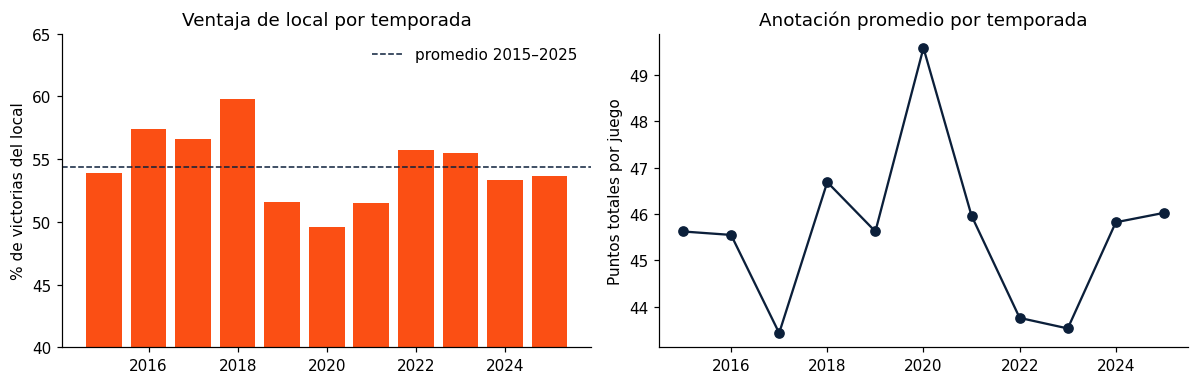

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.bar(por_temporada.index, 100 * por_temporada["victoria_local"], color="#FB4F14")
a1.axhline(100 * (r["result"] > 0).mean(), c="#0B1F3A", ls="--", lw=1, label="promedio 2015–2025")
a1.set(ylim=(40, 65), ylabel="% de victorias del local", title="Ventaja de local por temporada")
a1.legend(frameon=False)
a2.plot(por_temporada.index, por_temporada["puntos_totales"], marker="o", c="#0B1F3A")
a2.set(ylabel="Puntos totales por juego", title="Anotación promedio por temporada")
for ax in (a1, a2):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

**Lectura.** El local gana el 54.4 % de las veces, con variación entre temporadas de 49.6 % (2020, sin público por
la pandemia) a 59.8 % (2018). Por eso la línea base razonable es "siempre gana el local con la tasa histórica", y
la localía se modela como atributo. La anotación promedio también cambia entre años (43.4 a 49.6 puntos), lo que
justifica agregar la tendencia reciente de la liga al modelo del total de puntos.

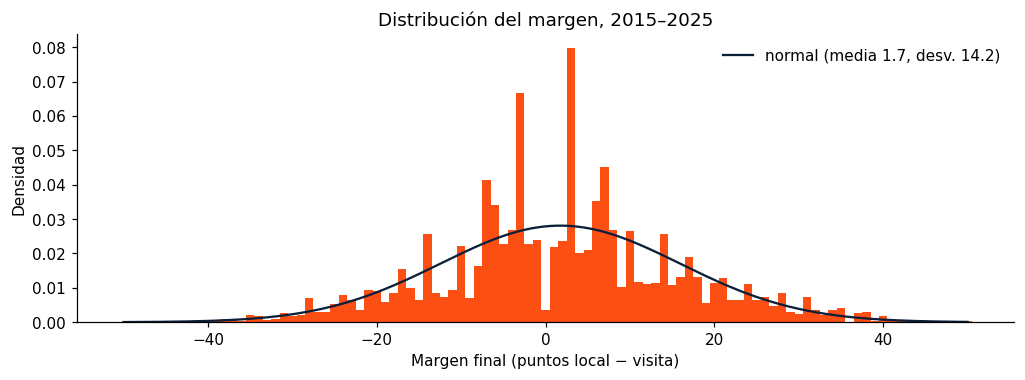

Diferencias más frecuentes (% de juegos): {3.0: 14.6, 7.0: 8.7, 6.0: 6.9, 14.0: 5.1, 10.0: 4.9}


In [6]:
margen = r["result"].dropna()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.hist(margen, bins=np.arange(-50.5, 51.5, 1), color="#FB4F14", density=True)
x = np.linspace(-50, 50, 400)
ax.plot(x, norm.pdf(x, margen.mean(), margen.std()), c="#0B1F3A", lw=1.5,
        label=f"normal (media {margen.mean():.1f}, desv. {margen.std():.1f})")
ax.set(xlabel="Margen final (puntos local − visita)", ylabel="Densidad", title="Distribución del margen, 2015–2025")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.show()

frecuentes = (margen.abs().value_counts(normalize=True).head(5) * 100).round(1)
print("Diferencias más frecuentes (% de juegos):", frecuentes.to_dict())

**Lectura.** El margen tiene media 1.7 (la ventaja local) y desviación de 14.2 puntos. Su forma general es
aproximadamente normal, por lo que más adelante la probabilidad de victoria se obtiene de una normal sobre el margen
predicho. Pero los valores son discretos: el 14.6 % de los juegos se decide por 3 puntos y el 8.7 % por 7. Por eso
un marcador predicho como 18–29 debe leerse como un valor esperado, no como el resultado más probable.

In [7]:
faltantes = (r[["temp", "wind", "surface", "roof", "home_qb_id", "spread_line", "home_moneyline"]]
             .isna().mean().mul(100).round(1).rename("% faltante"))
print(faltantes.to_string())
print("\nTemperatura faltante según el tipo de techo:")
pd.crosstab(r["roof"], r["temp"].isna(), margins=True).rename(columns={False: "con temp", True: "sin temp"})

temp              34.4
wind              34.4
surface            1.5
roof               0.0
home_qb_id         0.0
spread_line        0.0
home_moneyline     0.0

Temperatura faltante según el tipo de techo:


temp,con temp,sin temp,All
roof,,,
closed,1,384,385
dome,0,436,436
open,0,52,52
outdoors,1899,123,2022
All,1900,995,2895


**Lectura.** Temperatura y viento faltan en el 34.4 % de los juegos, pero no al azar: faltan en todos los juegos
con domo o techo cerrado, donde no aplican. Por eso en esos estadios se fijan condiciones controladas (70 °F, viento 0)
en lugar de imputar. Solo 123 juegos en exteriores y los de techo abierto quedan sin dato; esos se imputan con la
mediana del estadio en ese mes. Las líneas de apuestas están completas, así que sirven como referencia en todos los
juegos.

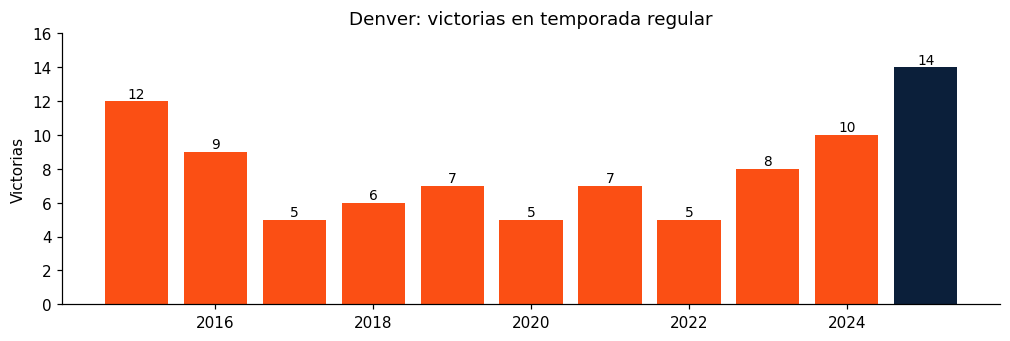

In [8]:
den_hist = r[(r["home_team"] == EQUIPO) | (r["away_team"] == EQUIPO)]
gano = np.where(den_hist["home_team"] == EQUIPO, den_hist["result"] > 0, den_hist["result"] < 0)
victorias_den = pd.Series(gano, index=den_hist["season"]).groupby(level=0).sum()
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(victorias_den.index, victorias_den, color=["#0B1F3A" if s == 2025 else "#FB4F14" for s in victorias_den.index])
for s, v in victorias_den.items():
    ax.text(s, v + 0.2, int(v), ha="center", fontsize=9)
ax.set(ylabel="Victorias", title="Denver: victorias en temporada regular", ylim=(0, 16))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Lectura.** Denver ganó entre 5 y 10 juegos por temporada de 2016 a 2024 y saltó a 14 en 2025. Ese salto es
justo lo que P3 pone a prueba: ¿un modelo con información previa a cada juego podía anticiparlo?

# Preprocesamiento

## Limpieza
- Se conservan juegos de temporada regular 2012–2025 (2012–2014 solo para iniciar Elo y medias móviles).
- Se unifican los códigos de equipos que se mudaron (OAK→LV, SD→LAC, STL→LA), para que su historial sea continuo.
- Clima: condiciones controladas bajo techo y mediana por estadio-mes en exteriores (ver sección 2c).
- El juego cancelado de 2022 se elimina. Los empates cuentan como "no victoria local" y se excluyen al entrenar.

In [9]:
def limpiar(g: pd.DataFrame, hasta: int = TEMPORADA_PRUEBA, incluir_pendientes: bool = False) -> pd.DataFrame:
    """Filtra temporada regular, unifica equipos e imputa clima."""
    g = g[(g["game_type"] == "REG")
          & g["season"].between(PRIMERA_TEMPORADA - TEMPORADAS_CALENTAMIENTO, hasta)].copy()
    pendiente = g["result"].isna() & (g["season"] == hasta) & incluir_pendientes
    g = g[g["result"].notna() | pendiente].copy()
    g["pendiente"] = pendiente[g.index].astype(int)
    for col in ["home_team", "away_team"]:
        g[col] = g[col].replace(UNIFICAR_EQUIPOS)
    g["gameday"] = pd.to_datetime(g["gameday"])
    g = g.sort_values(["gameday", "game_id"]).reset_index(drop=True)
    g["y"] = (g["result"] > 0).astype(int)
    g["empate"] = (g["result"] == 0).astype(int)
    g["neutral"] = (g["location"] == "Neutral").astype(int)
    g["bajo_techo"] = g["roof"].isin(["dome", "closed"]).astype(int)
    g["temp_faltante"] = g["temp"].isna().astype(int)
    # bajo techo: condiciones controladas
    g["temp"] = np.where(g["bajo_techo"] == 1, g["temp"].fillna(70), g["temp"])
    g["wind"] = np.where(g["bajo_techo"] == 1, g["wind"].fillna(0), g["wind"])
    g["mes"] = g["gameday"].dt.month
    # exteriores: mediana estadio-mes calculada solo con temporadas de entrenamiento
    ref = g[g["season"] < TEMPORADA_PRUEBA]
    clave = pd.MultiIndex.from_frame(g[["stadium_id", "mes"]])
    for col in ["temp", "wind"]:
        mediana = ref.groupby(["stadium_id", "mes"])[col].median().reindex(clave).to_numpy()
        g[col] = g[col].fillna(pd.Series(mediana, index=g.index))
        g[col] = g[col].fillna(ref[col].median())
    g["cesped_artificial"] = (~g["surface"].fillna("").str.contains("grass")).astype(int)
    g["techo_abierto"] = (g["roof"] == "open").astype(int)
    return g

## Ingeniería de atributos
La regla central es **no usar información posterior al juego** (fuga de información). Por eso:
- El **Elo** se guarda *antes* de cada juego y se actualiza después. Usa la variante de FiveThirtyEight: K = 20,
  ventaja local de 48 puntos, multiplicador por margen y regreso de un tercio a la media entre temporadas.
- Las **medias móviles** (margen de 3, 5 y 8 juegos; puntos a favor y en contra de 5) usan `shift(1)`, es decir,
  excluyen el juego actual.
- El **récord de la temporada** se encoge hacia 0.5 con dos juegos ficticios, para que un 1–0 no cuente como 100 %.
- Cambio de mariscal, entrenador nuevo y descanso largo se conocen antes del juego.

Casi todo se expresa como **diferencia local − visita**, porque lo que predice el resultado es la fuerza relativa.

In [10]:
def calcular_elo(g: pd.DataFrame) -> pd.DataFrame:
    """Agrega el Elo previo a cada juego y la probabilidad que implica."""
    elo: dict[str, float] = {}
    temporada_actual = None
    pre_local, pre_visita = [], []
    for fila in g.itertuples():
        if fila.season != temporada_actual:  # nueva temporada: regreso a la media
            elo = {t: v + ELO_REVERSION * (ELO_INICIAL - v) for t, v in elo.items()}
            temporada_actual = fila.season
        el = elo.get(fila.home_team, ELO_INICIAL)
        ev = elo.get(fila.away_team, ELO_INICIAL)
        pre_local.append(el)
        pre_visita.append(ev)  # se guarda antes de actualizar
        if pd.isna(fila.result):  # pendiente: no actualiza
            continue
        ventaja = 0 if fila.neutral else ELO_LOCAL
        dif = el + ventaja - ev
        esperado = 1 / (1 + 10 ** (-dif / 400))
        real = 1.0 if fila.result > 0 else 0.0 if fila.result < 0 else 0.5
        margen = abs(fila.result)
        dif_ganador = dif if fila.result > 0 else -dif
        # multiplicador por margen, corregido por autocorrelación
        mult = np.log(margen + 1) * 2.2 / (dif_ganador * 0.001 + 2.2) if margen > 0 else 1.0
        cambio = ELO_K * mult * (real - esperado)
        elo[fila.home_team] = el + cambio
        elo[fila.away_team] = ev - cambio
    g = g.copy()
    g["elo_local"] = pre_local
    g["elo_visita"] = pre_visita
    ventaja = np.where(g["neutral"] == 1, 0, ELO_LOCAL)
    g["prob_elo"] = 1 / (1 + 10 ** (-(g["elo_local"] + ventaja - g["elo_visita"]) / 400))
    return g

In [11]:
def atributos_por_equipo(g: pd.DataFrame) -> pd.DataFrame:
    """Atributos de cada equipo previos al juego (una fila por equipo y juego)."""
    local = pd.DataFrame({
        "game_id": g["game_id"], "season": g["season"], "gameday": g["gameday"],
        "team": g["home_team"], "pf": g["home_score"], "pa": g["away_score"],
        "qb": g["home_qb_id"], "coach": g["home_coach"], "rest": g["home_rest"], "lado": "home"})
    visita = pd.DataFrame({
        "game_id": g["game_id"], "season": g["season"], "gameday": g["gameday"],
        "team": g["away_team"], "pf": g["away_score"], "pa": g["home_score"],
        "qb": g["away_qb_id"], "coach": g["away_coach"], "rest": g["away_rest"], "lado": "away"})
    t = pd.concat([local, visita]).sort_values(["team", "gameday"]).reset_index(drop=True)
    t["margen"] = t["pf"] - t["pa"]
    t["gano"] = ((t["margen"] > 0).astype(float) + 0.5 * (t["margen"] == 0)).where(t["margen"].notna())
    t["qb"] = t.groupby("team")["qb"].ffill()
    t["coach"] = t.groupby("team")["coach"].ffill()

    # shift(1): solo juegos anteriores
    por_eq = t.groupby("team", group_keys=False)
    for v in [3, 5, 8]:
        t[f"margen_m{v}"] = por_eq["margen"].transform(lambda s: s.shift(1).rolling(v, min_periods=1).mean())
    t["pf_m5"] = por_eq["pf"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    t["pa_m5"] = por_eq["pa"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    moviles = ["margen_m3", "margen_m5", "margen_m8", "pf_m5", "pa_m5"]
    t[moviles] = t.groupby("team")[moviles].ffill()

    por_temp = t.groupby(["team", "season"], group_keys=False)
    juegos_prev = por_temp["margen"].transform(lambda s: s.shift(1).notna().cumsum())
    victorias_prev = por_temp["gano"].transform(lambda s: s.shift(1).fillna(0).cumsum())
    # récord encogido hacia 0.5 con dos juegos ficticios
    t["pct_temporada"] = (victorias_prev + 1) / (juegos_prev + 2)
    margen_prev = por_temp["margen"].transform(lambda s: s.shift(1).fillna(0).cumsum())
    t["margen_temporada"] = margen_prev / (juegos_prev + 2)

    # récord de la temporada anterior
    final = t.groupby(["team", "season"])["gano"].mean().rename("pct_previa").reset_index()
    final["season"] += 1
    t = t.merge(final, on=["team", "season"], how="left")
    t["pct_previa"] = t["pct_previa"].fillna(0.5)

    t = t.sort_values(["team", "gameday"]).reset_index(drop=True)
    t["cambio_qb"] = (t.groupby("team")["qb"].shift(1) != t["qb"]).astype(int)
    primera_temp_coach = t.groupby(["team", "coach"])["season"].transform("min")
    t["coach_nuevo"] = (t["season"] == primera_temp_coach).astype(int)
    t["descanso_largo"] = (t["rest"] >= 10).astype(int)
    return t

In [12]:
ATRIBUTOS_EQUIPO = ["margen_m3", "margen_m5", "margen_m8", "pf_m5", "pa_m5", "pct_temporada",
                    "margen_temporada", "pct_previa", "cambio_qb", "coach_nuevo", "descanso_largo"]


def construir_tabla(g: pd.DataFrame) -> pd.DataFrame:
    """Una fila por juego con atributos del local, de la visita y sus diferencias."""
    g = calcular_elo(g)
    t = atributos_por_equipo(g)
    loc = t[t["lado"] == "home"].set_index("game_id")[ATRIBUTOS_EQUIPO].add_suffix("_local")
    vis = t[t["lado"] == "away"].set_index("game_id")[ATRIBUTOS_EQUIPO].add_suffix("_visita")
    df = g.set_index("game_id").join(loc).join(vis).reset_index()

    # diferencias local − visita
    df["dif_elo"] = df["elo_local"] - df["elo_visita"]
    for a in ATRIBUTOS_EQUIPO:
        df[f"dif_{a}"] = df[f"{a}_local"] - df[f"{a}_visita"]
    df["dif_descanso"] = df["home_rest"] - df["away_rest"]
    df["local_real"] = 1 - df["neutral"]
    return df[df["season"] >= PRIMERA_TEMPORADA].reset_index(drop=True)


CANDIDATOS = (
    ["dif_elo", "dif_descanso", "local_real", "div_game", "bajo_techo", "techo_abierto",
     "cesped_artificial", "temp", "wind", "week"]
    + [f"dif_{a}" for a in ATRIBUTOS_EQUIPO]
    + ["cambio_qb_local", "cambio_qb_visita", "coach_nuevo_local", "coach_nuevo_visita"]
)

In [13]:
rng = np.random.default_rng(SEMILLA)  # bootstrap de clasificación
resumen: dict = {}  # se guarda en resumen.json
df = construir_tabla(limpiar(crudo))
resumen["datos"] = {
    "juegos_regulares_2015_2025": int(len(estudio)),
    "juegos_sin_resultado (cancelado)": int(estudio["result"].isna().sum()),
    "juegos_modelados": int(len(df)),
    "empates": int(df["empate"].sum()),
    "juegos_neutrales": int(df["neutral"].sum()),
    "columnas_originales": int(crudo.shape[1]),
    "victoria_local_%": round(100 * df["y"].mean(), 1),
}
print("Datos:", json.dumps(resumen["datos"], ensure_ascii=False))

# los empates se excluyen al entrenar
entrenamiento = df[(df["season"] < TEMPORADA_PRUEBA) & (df["empate"] == 0)]
prueba = df[df["season"] == TEMPORADA_PRUEBA].copy()

Datos: {"juegos_regulares_2015_2025": 2895, "juegos_sin_resultado (cancelado)": 0, "juegos_modelados": 2895, "empates": 10, "juegos_neutrales": 49, "columnas_originales": 46, "victoria_local_%": 54.4}


## Selección de atributos (solo con el entrenamiento 2015–2024)
1. **Filtro de correlación:** en cada par con |r| > 0.9 se elimina el atributo menos correlacionado con el objetivo,
   porque dos atributos casi iguales no agregan información y vuelven inestables los coeficientes.
2. **Regresión logística L1:** su penalización deja en cero los atributos que no ayudan a predecir; el valor de C
   se elige con los pliegues de validación temporal (Modelado).
3. **VIF:** si quedara colinealidad fuerte (VIF > 10) se agregaría un modelo con PCA.

La selección usa solo datos de entrenamiento, para no filtrar información de 2025.

In [14]:
def filtro_correlacion(X: pd.DataFrame, y: pd.Series, umbral: float = 0.9) -> list[str]:
    """En pares con |r| > umbral quita el menos correlacionado con y."""
    corr = X.corr().abs()
    rel = X.apply(lambda c: abs(np.corrcoef(c, y)[0, 1]))
    eliminar: set[str] = set()
    cols = list(X.columns)
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            if a in eliminar or b in eliminar:
                continue
            if corr.loc[a, b] > umbral:
                eliminar.add(a if rel[a] < rel[b] else b)
    return [c for c in cols if c not in eliminar]


def vif(X: pd.DataFrame) -> pd.Series:
    """VIF: diagonal de la inversa de la matriz de correlación."""
    Z = StandardScaler().fit_transform(X)
    inv = np.linalg.pinv(np.corrcoef(Z, rowvar=False))
    return pd.Series(np.diag(inv), index=X.columns)

## Tabla de la extensión (marcador)
Se agregan a la misma tabla el ataque y la defensa de cada equipo por separado y el promedio de puntos totales de los
últimos 128 juegos de la liga (≈ media temporada), porque el total de puntos depende de la tendencia de anotación de
cada época (Análisis exploratorio). Aquí sí se conservan los juegos pendientes de 2026, para poder pronosticarlos.

In [15]:
ELO_POR_PUNTO = 25  # puntos Elo por punto de marcador

# atributos del modelo de marcador
ATRIBUTOS = [
    "dif_elo", "dif_margen_m3", "dif_margen_m8", "dif_pct_temporada", "dif_pct_previa",
    "pf_m5_local", "pa_m5_local", "pf_m5_visita", "pa_m5_visita",
    "margen_temporada_local", "margen_temporada_visita",
    "local_real", "div_game", "week", "dif_descanso", "descanso_largo_local", "descanso_largo_visita",
    "cambio_qb_local", "cambio_qb_visita", "coach_nuevo_local", "coach_nuevo_visita",
    "bajo_techo", "techo_abierto", "cesped_artificial", "temp", "wind",
    "liga_total_m",
]

In [16]:
def preparar(crudo: pd.DataFrame, temporada_actual: int) -> pd.DataFrame:
    """Tabla del marcador, con los juegos pendientes de la temporada actual."""
    g = limpiar(crudo, hasta=temporada_actual, incluir_pendientes=True)
    total = (g["home_score"] + g["away_score"]).shift(1)
    g["liga_total_m"] = total.rolling(128, min_periods=32).mean()
    # mismo valor para todo el día: evita usar juegos de horas posteriores
    g["liga_total_m"] = g.groupby("gameday")["liga_total_m"].transform("first")
    g["liga_total_m"] = g["liga_total_m"].ffill()
    df = construir_tabla(g)
    df["margen"] = df["home_score"] - df["away_score"]
    df["total"] = df["home_score"] + df["away_score"]
    return df

In [17]:
rng_m = np.random.default_rng(SEMILLA)  # bootstrap del marcador
dm = preparar(crudo, TEMPORADA_ACTUAL)
jugados_m = dm[dm["pendiente"] == 0]
ent_m = jugados_m[jugados_m["season"] < TEMPORADA_PRUEBA]
prueba_m = jugados_m[jugados_m["season"] == TEMPORADA_PRUEBA]
resumen_m = {}
print(f"Tabla del marcador: {len(dm):,} juegos ({(dm['pendiente'] == 1).sum()} pendientes de 2026)")

Tabla del marcador: 3,167 juegos (114 pendientes de 2026)


# Modelado

## Probabilidad de victoria (clasificación)
Se comparan modelos de distinta complejidad, cada uno con una razón:
- **Base:** siempre la tasa local del entrenamiento (54.7 %). Es el mínimo a superar.
- **Elo:** la probabilidad que da la diferencia de Elo, sin aprendizaje. Mide cuánto aporta un solo número.
- **Regresión logística L1:** interpretable y adecuada para ~2,600 juegos.
- **Random forest y boosting:** captan interacciones no lineales entre atributos.
- **Naive Bayes:** referencia simple.
- **Apuestas:** probabilidad implícita del moneyline sin comisión; referencia externa, no entra al entrenamiento.

**Validación temporal.** Los hiperparámetros se eligen por log-loss medio en dos pliegues de ventana creciente
(2015–2022 → 2023 y 2015–2023 → 2024). No se usa validación cruzada aleatoria porque mezclaría juegos futuros en el
entrenamiento. El modelo final se entrena con 2015–2024 y se prueba una sola vez en 2025.

In [18]:
def pliegues(df: pd.DataFrame):
    """Pliegues de ventana creciente; sin empates al entrenar."""
    for fin_ent, val in PLIEGUES:
        ent = df[(df["season"] <= fin_ent) & (df["empate"] == 0)]
        yield fin_ent, val, ent, df[df["season"] == val]


def logistica_l1(C: float) -> LogisticRegression:
    # sklearn ≥ 1.8 reemplaza penalty por l1_ratio
    version = tuple(int(x) for x in sklearn.__version__.split(".")[:2])
    if version >= (1, 8):
        return LogisticRegression(l1_ratio=1.0, solver="liblinear", C=C, max_iter=2000)
    return LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=2000)


def crear_modelo(nombre: str, params: dict):
    """Clasificador sin entrenar según nombre e hiperparámetros."""
    if nombre == "Regresión logística":
        return make_pipeline(StandardScaler(), logistica_l1(params["C"]))
    if nombre == "Random forest":
        return RandomForestClassifier(n_estimators=500, min_samples_leaf=params["min_samples_leaf"],
                                      max_features=params["max_features"], n_jobs=-1, random_state=SEMILLA)
    if nombre == "Boosting":
        return HistGradientBoostingClassifier(learning_rate=params["learning_rate"],
                                              max_depth=params["max_depth"], max_iter=params["max_iter"],
                                              l2_regularization=1.0, random_state=SEMILLA)
    if nombre == "Naive Bayes":
        return make_pipeline(StandardScaler(), GaussianNB())
    if nombre == "Logística + PCA":
        return make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=SEMILLA),
                             LogisticRegression(C=params["C"], max_iter=2000))
    raise ValueError(nombre)


REJILLAS = {
    "Regresión logística": [{"C": c} for c in [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]],
    "Random forest": [{"min_samples_leaf": l, "max_features": m}
                      for l in [10, 25, 50] for m in ["sqrt", 0.5]],
    "Boosting": [{"learning_rate": lr, "max_depth": d, "max_iter": n}
                 for lr in [0.02, 0.05] for d in [2, 3] for n in [100, 300]],
    "Naive Bayes": [{}],
    "Logística + PCA": [{"C": c} for c in [0.01, 0.1, 1.0]],
}


def ajustar_hiperparametros(df, atributos, nombre):
    """Rejilla por log-loss medio en los pliegues temporales."""
    mejor, mejor_ll = None, np.inf
    for params in REJILLAS[nombre]:
        lls = []
        for _, _, ent, val in pliegues(df):
            m = crear_modelo(nombre, params).fit(ent[atributos], ent["y"])
            lls.append(log_loss(val["y"], m.predict_proba(val[atributos])[:, 1], labels=[0, 1]))
        if np.mean(lls) < mejor_ll:
            mejor, mejor_ll = params, np.mean(lls)
    return mejor, mejor_ll


def prob_apuestas(df: pd.DataFrame) -> pd.Series:
    """Probabilidad implícita del moneyline, sin comisión."""
    def implicita(ml):
        return np.where(ml < 0, -ml / (-ml + 100), 100 / (ml + 100))
    pl, pv = implicita(df["home_moneyline"]), implicita(df["away_moneyline"])
    return pd.Series(pl / (pl + pv), index=df.index)

In [19]:
# 1) correlación, 2) L1, 3) VIF; solo con 2015–2024
tras_filtro = filtro_correlacion(entrenamiento[CANDIDATOS], entrenamiento["y"])
eliminados_corr = [c for c in CANDIDATOS if c not in tras_filtro]
C_l1, _ = ajustar_hiperparametros(df, tras_filtro, "Regresión logística")
l1 = crear_modelo("Regresión logística", C_l1).fit(entrenamiento[tras_filtro], entrenamiento["y"])
coef = pd.Series(l1[-1].coef_[0], index=tras_filtro)
seleccion = list(coef[coef != 0].index) or tras_filtro  # coeficientes no nulos
vifs = vif(entrenamiento[seleccion])
usar_pca = bool(vifs.max() > 10)
resumen["seleccion"] = {
    "candidatos": len(CANDIDATOS),
    "eliminados_por_|r|>0.9": eliminados_corr,
    "C_L1": C_l1["C"],
    "eliminados_por_L1": [c for c in tras_filtro if c not in seleccion],
    "seleccionados": seleccion,
    "VIF_max": round(float(vifs.max()), 2),
    "se_agrega_PCA": usar_pca,
}
print("Selección:", json.dumps(resumen["seleccion"], ensure_ascii=False))

Selección: {"candidatos": 25, "eliminados_por_|r|>0.9": ["dif_descanso"], "C_L1": 0.1, "eliminados_por_L1": ["local_real", "techo_abierto", "cesped_artificial", "temp", "wind", "dif_margen_m3", "dif_margen_m5", "dif_pa_m5", "dif_pct_temporada", "dif_margen_temporada", "dif_pct_previa", "dif_coach_nuevo", "cambio_qb_visita", "coach_nuevo_local", "coach_nuevo_visita"], "seleccionados": ["dif_elo", "div_game", "bajo_techo", "week", "dif_margen_m8", "dif_pf_m5", "dif_cambio_qb", "dif_descanso_largo", "cambio_qb_local"], "VIF_max": 4.07, "se_agrega_PCA": false}


**Resultado.** De 25 candidatos, el filtro de correlación quitó 1 (`dif_descanso`, casi igual a `dif_descanso_largo`) y la logística L1 con C = 0.1 quitó 15. Quedaron 9 atributos: diferencia de Elo, margen de los últimos 8 juegos, puntos a favor de los últimos 5, dos indicadores de cambio de mariscal, semana, descanso largo, juego divisional y bajo techo. El VIF máximo es 4.07, así que no hay colinealidad fuerte y no se agrega el modelo con PCA.

In [20]:
nombres = ["Regresión logística", "Random forest", "Boosting", "Naive Bayes"]
if usar_pca:
    nombres.append("Logística + PCA")
tasa_local = entrenamiento["y"].mean()
preds = {"Base (tasa local)": np.full(len(prueba), tasa_local),
         "Elo": prueba["prob_elo"].to_numpy()}
hiper = {}
ll_validacion = {}  # para elegir el modelo sin ver 2025
ajustados = {}
for n in nombres:
    params, ll_val = ajustar_hiperparametros(df, seleccion, n)
    ll_validacion[n] = ll_val
    hiper[n] = {"params": params, "log_loss_validacion": round(ll_val, 4)}
    ajustados[n] = crear_modelo(n, params).fit(entrenamiento[seleccion], entrenamiento["y"])
    preds[n] = ajustados[n].predict_proba(prueba[seleccion])[:, 1]
    print(f"  {n}: {params}  log-loss validación = {ll_val:.4f}")
resumen["hiperparametros"] = hiper
tiene_apuesta = prueba[["home_moneyline", "away_moneyline"]].notna().all(axis=1)
p_apuesta = prob_apuestas(prueba[tiene_apuesta])

  Regresión logística: {'C': 1.0}  log-loss validación = 0.6357
  Random forest: {'min_samples_leaf': 50, 'max_features': 'sqrt'}  log-loss validación = 0.6359
  Boosting: {'learning_rate': 0.02, 'max_depth': 3, 'max_iter': 300}  log-loss validación = 0.6362
  Naive Bayes: {}  log-loss validación = 0.7546


**Resultado.** Los hiperparámetros elegidos por log-loss de validación son C = 1 en la logística; hoja mínima de 50 y raíz del número de atributos por división en el bosque; y tasa 0.02, profundidad 3 y 300 iteraciones en el boosting. Logística, bosque y boosting quedan prácticamente empatados en validación (log-loss de 0.6357 a 0.6362; Naive Bayes, 0.755), por lo que la comparación que cuenta es la de la prueba en 2025.

## Marcador (regresión)
Se predicen dos cantidades: el **margen** (local − visita) y el **total** de puntos; los puntos de cada equipo salen
de `local = (total + margen) / 2` y `visita = (total − margen) / 2`. Se comparan Ridge, random forest y boosting con los
mismos pliegues, eligiendo por error absoluto medio (MAE). La **probabilidad de victoria** es P(margen > 0) con error
normal (Análisis exploratorio), y el **rango del 80 %** usa los percentiles 10 y 90 de los errores de validación.

In [21]:
# mismas rejillas que en clasificación para los árboles
REJILLAS_REG = {
    "Ridge": [{"alpha": a} for a in [1, 10, 100, 1000]],
    "Random forest": REJILLAS["Random forest"],
    "Boosting": REJILLAS["Boosting"],
}


def crear_regresor(nombre: str, p: dict):
    """Regresor sin entrenar según nombre e hiperparámetros."""
    if nombre == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=p["alpha"]))
    if nombre == "Random forest":
        return RandomForestRegressor(n_estimators=500, min_samples_leaf=p["min_samples_leaf"],
                                     max_features=p["max_features"], n_jobs=-1, random_state=SEMILLA)
    if nombre == "Boosting":
        return HistGradientBoostingRegressor(learning_rate=p["learning_rate"], max_depth=p["max_depth"],
                                             max_iter=p["max_iter"], l2_regularization=1.0,
                                             random_state=SEMILLA)
    raise ValueError(nombre)


def pliegues_reg(df):
    """Mismos pliegues que en clasificación, sin juegos pendientes."""
    for fin, val in PLIEGUES:
        yield df[(df["season"] <= fin) & (df["pendiente"] == 0)], df[df["season"] == val]


def elegir(df, objetivo):
    """Modelo e hiperparámetros con menor MAE de validación; devuelve también sus residuos."""
    resultados = []
    for nombre, rejilla in REJILLAS_REG.items():
        for p in rejilla:
            maes, residuos = [], []
            for ent, val in pliegues_reg(df):
                m = crear_regresor(nombre, p).fit(ent[ATRIBUTOS], ent[objetivo])
                pred = m.predict(val[ATRIBUTOS])
                maes.append(mean_absolute_error(val[objetivo], pred))
                residuos.append(val[objetivo].to_numpy() - pred)
            resultados.append((np.mean(maes), nombre, p, np.concatenate(residuos)))
    resultados.sort(key=lambda r: r[0])
    mae, nombre, p, res = resultados[0]
    por_modelo = {}
    for r in resultados:  # mejor configuración de cada modelo
        por_modelo.setdefault(r[1], {"params": r[2], "MAE_validacion": round(r[0], 3)})
    return nombre, p, res, por_modelo

In [22]:
class ModeloMarcador:
    """Predice margen y total; de ahí salen los puntos, P(victoria) y rangos del 80 %."""

    def __init__(self, sel_margen, sel_total):
        self.sel = {"margen": sel_margen, "total": sel_total}

    def fit(self, ent):
        self.m = {o: crear_regresor(n, p).fit(ent[ATRIBUTOS], ent[o]) for o, (n, p, _) in self.sel.items()}
        # incertidumbre a partir de los residuos de validación
        res_m, res_t = self.sel["margen"][2], self.sel["total"][2]
        self.sigma_margen = float(np.std(res_m))
        self.q_local = np.percentile((res_t + res_m) / 2, [10, 90])
        self.q_visita = np.percentile((res_t - res_m) / 2, [10, 90])
        return self

    def predict(self, df):
        M = self.m["margen"].predict(df[ATRIBUTOS])
        T = self.m["total"].predict(df[ATRIBUTOS])
        out = pd.DataFrame(index=df.index)
        out["margen_pred"], out["total_pred"] = M, T
        out["pts_local_pred"] = np.clip((T + M) / 2, 0, None)
        out["pts_visita_pred"] = np.clip((T - M) / 2, 0, None)
        out["p_local"] = norm.cdf(M / self.sigma_margen)  # P(margen > 0), error normal
        out["local_p10"] = np.clip(out["pts_local_pred"] + self.q_local[0], 0, None)
        out["local_p90"] = out["pts_local_pred"] + self.q_local[1]
        out["visita_p10"] = np.clip(out["pts_visita_pred"] + self.q_visita[0], 0, None)
        out["visita_p90"] = out["pts_visita_pred"] + self.q_visita[1]
        return out

In [23]:
def evaluar(df_eval, pred, nombre):
    """Métricas del marcador y del ganador para un conjunto de predicciones."""
    y_m, y_t = df_eval["margen"], df_eval["total"]
    gano_local = (y_m > 0).astype(int)
    no_empate = y_m != 0
    return {
        "modelo": nombre,
        "MAE_margen": mean_absolute_error(y_m, pred["margen_pred"]),
        "MAE_total": mean_absolute_error(y_t, pred["total_pred"]),
        "MAE_pts_local": mean_absolute_error(df_eval["home_score"], pred["pts_local_pred"]),
        "MAE_pts_visita": mean_absolute_error(df_eval["away_score"], pred["pts_visita_pred"]),
        "acierta_ganador_%": 100 * np.mean((pred["margen_pred"][no_empate] > 0) == (y_m[no_empate] > 0)),
        "margen_a_7_pts_%": 100 * np.mean(np.abs(y_m - pred["margen_pred"]) <= 7),
        "log_loss_ganador": log_loss(gano_local, np.clip(pred["p_local"], 1e-6, 1 - 1e-6), labels=[0, 1])
        if "p_local" in pred else np.nan,
    }


def pred_referencia(df, tipo, ent=None, sigma=13.5):
    """Predicciones de referencia: base (promedios), Elo o apuestas."""
    out = pd.DataFrame(index=df.index)
    if tipo == "base":
        M = np.full(len(df), ent["margen"].mean())
        T = np.full(len(df), ent["total"].mean())
    elif tipo == "elo":
        ventaja = np.where(df["neutral"] == 1, 0, ELO_LOCAL)
        M = ((df["dif_elo"] + ventaja) / ELO_POR_PUNTO).to_numpy()
        T = np.full(len(df), ent["total"].mean())
    elif tipo == "apuestas":  # spread y over/under
        M, T = df["spread_line"].to_numpy(), df["total_line"].to_numpy()
    out["margen_pred"], out["total_pred"] = M, T
    out["pts_local_pred"], out["pts_visita_pred"] = (T + M) / 2, (T - M) / 2
    out["p_local"] = norm.cdf(M / sigma)
    return out

In [24]:
def guardar_pronostico(pend, pp, semana, temporada, carpeta="pronosticos"):
    """Guarda el pronóstico de una semana antes de jugarse."""
    os.makedirs(carpeta, exist_ok=True)
    hoy = FECHA_DATOS  # fecha de la copia de datos, no del reloj
    sel = pend["week"] == semana
    j = pend[sel]
    out = pd.DataFrame({
        "game_id": j["game_id"], "temporada": temporada, "semana": j["week"],
        "fecha": j["gameday"].dt.strftime("%Y-%m-%d"), "visita": j["away_team"], "local": j["home_team"],
        "pts_visita_pred": pp.loc[sel, "pts_visita_pred"].round(1),
        "pts_local_pred": pp.loc[sel, "pts_local_pred"].round(1),
        "visita_p10": pp.loc[sel, "visita_p10"].round(1), "visita_p90": pp.loc[sel, "visita_p90"].round(1),
        "local_p10": pp.loc[sel, "local_p10"].round(1), "local_p90": pp.loc[sel, "local_p90"].round(1),
        "p_local": pp.loc[sel, "p_local"].round(3),
        "spread_line": j["spread_line"], "total_line": j["total_line"], "generado": hoy,
    })
    ruta = f"{carpeta}/pronostico_{temporada}_semana{semana:02d}_generado_{hoy}.csv"
    out.to_csv(ruta, index=False)
    print(f"Pronóstico guardado en {ruta} (se revisa en «Revisión del pronóstico»)")


def formatear(juegos, pred, con_real):
    """Tabla legible de marcadores predichos (y reales si los hay)."""
    t = pd.DataFrame({
        "semana": juegos["week"].to_numpy(),
        "fecha": juegos["gameday"].dt.strftime("%Y-%m-%d").to_numpy(),
        "visita": juegos["away_team"].to_numpy(),
        "local": juegos["home_team"].to_numpy(),
        "pred": [f"{v:.0f}–{l:.0f}" for v, l in zip(pred["pts_visita_pred"], pred["pts_local_pred"])],
        "rango_80%_visita": [f"{a:.0f}–{b:.0f}" for a, b in zip(pred["visita_p10"], pred["visita_p90"])],
        "rango_80%_local": [f"{a:.0f}–{b:.0f}" for a, b in zip(pred["local_p10"], pred["local_p90"])],
        "P(gana local)": pred["p_local"].round(2).to_numpy(),
    })
    if con_real:
        t["real"] = [f"{v:.0f}–{l:.0f}" for v, l in zip(juegos["away_score"], juegos["home_score"])]
        t["acierta_ganador"] = np.sign(pred["margen_pred"].to_numpy()) == np.sign(juegos["margen"].to_numpy())
    else:
        apuesta = juegos[["spread_line", "total_line"]]
        t["apuestas"] = [f"{(tt - s) / 2:.1f}–{(tt + s) / 2:.1f}" if pd.notna(s) and pd.notna(tt) else "—"
                         for s, tt in zip(apuesta["spread_line"], apuesta["total_line"])]
    return t

In [25]:
sel = {}
for objetivo in ["margen", "total"]:
    nombre, p, res, por_modelo = elegir(dm, objetivo)
    sel[objetivo] = (nombre, p, res)
    resumen_m[f"seleccion_{objetivo}"] = {"elegido": nombre, "params": p, "candidatos": por_modelo}
    print(f"{objetivo}: elegido {nombre} {p}")
    for n, info in por_modelo.items():
        print(f"    {n:14s} MAE validación = {info['MAE_validacion']:.3f}  {info['params']}")

modelo = ModeloMarcador(sel["margen"], sel["total"]).fit(ent_m)
print(f"Desviación del error de margen (validación): {modelo.sigma_margen:.2f} puntos")

margen: elegido Ridge {'alpha': 1}
    Ridge          MAE validación = 10.176  {'alpha': 1}
    Random forest  MAE validación = 10.241  {'min_samples_leaf': 50, 'max_features': 'sqrt'}
    Boosting       MAE validación = 10.254  {'learning_rate': 0.02, 'max_depth': 2, 'max_iter': 300}
total: elegido Random forest {'min_samples_leaf': 50, 'max_features': 0.5}
    Random forest  MAE validación = 10.212  {'min_samples_leaf': 50, 'max_features': 0.5}
    Boosting       MAE validación = 10.218  {'learning_rate': 0.02, 'max_depth': 3, 'max_iter': 100}
    Ridge          MAE validación = 10.248  {'alpha': 100}
Desviación del error de margen (validación): 13.21 puntos


**Resultado.** Para el margen se elige Ridge (α = 1) y para el total un random forest (hoja mínima de 50, la mitad de los atributos por división). El margen depende casi linealmente de la diferencia de fuerza, mientras que el total depende de combinaciones (ataque de uno contra defensa del otro, tendencia de la liga), que los árboles captan mejor. La desviación del error de margen en validación es 13.2 puntos, cercana a la desviación del margen real (14.2): con estos atributos el margen sigue siendo muy incierto.

# Evaluación

# ¿Supera el modelo a la línea base en 2025?
Métricas: **log-loss** (castiga más equivocarse con seguridad), **Brier** (error cuadrático de la probabilidad) y
exactitud. La incertidumbre de la mejora se estima con un **bootstrap que remuestrea semanas completas**, porque los
juegos de una misma semana comparten contexto. Un modelo *supera* a la base si el IC 95 % de Δ = modelo − base queda
completo bajo cero en log-loss y Brier.

In [26]:
def remuestreo_semanas(semanas, B, rng):
    """Genera B remuestreos de semanas completas (índices de filas)."""
    unicas = np.unique(semanas)
    idx = {w: np.where(semanas == w)[0] for w in unicas}
    for _ in range(B):
        yield np.concatenate([idx[w] for w in rng.choice(unicas, size=len(unicas), replace=True)])


def bootstrap_semanas(prueba, p_modelo, p_base, B, rng):
    """IC 95 % de Δlog-loss y ΔBrier (modelo − base)."""
    y = prueba["y"].to_numpy()
    eps = 1e-15
    ll_m = -(y * np.log(np.clip(p_modelo, eps, 1)) + (1 - y) * np.log(np.clip(1 - p_modelo, eps, 1)))
    ll_b = -(y * np.log(p_base) + (1 - y) * np.log(1 - p_base))
    br_m, br_b = (p_modelo - y) ** 2, (p_base - y) ** 2
    d_ll, d_br = [], []
    for filas in remuestreo_semanas(prueba["week"].to_numpy(), B, rng):
        d_ll.append(ll_m[filas].mean() - ll_b[filas].mean())
        d_br.append(br_m[filas].mean() - br_b[filas].mean())
    return np.percentile(d_ll, [2.5, 97.5]), np.percentile(d_br, [2.5, 97.5])


def bootstrap_mae(semanas, err_m, err_b, B, rng):
    """IC 95 % de ΔMAE (modelo − base)."""
    d = [err_m[f].mean() - err_b[f].mean() for f in remuestreo_semanas(semanas, B, rng)]
    return np.percentile(d, [2.5, 97.5])


def poisson_binomial(probs: np.ndarray) -> np.ndarray:
    """Distribución exacta del número de victorias."""
    dist = np.array([1.0])
    for p in probs:
        dist = np.convolve(dist, [1 - p, p])
    return dist


def intervalo(dist: np.ndarray, nivel: float = 0.90) -> tuple[int, int]:
    """Intervalo central de una distribución discreta."""
    acum = np.cumsum(dist)
    a = (1 - nivel) / 2
    return int(np.searchsorted(acum, a)), int(np.searchsorted(acum, 1 - a))

In [27]:
filas = []
for n, p in preds.items():
    fila = {"modelo": n,
            "log_loss": log_loss(prueba["y"], p, labels=[0, 1]),
            "brier": brier_score_loss(prueba["y"], p),
            "exactitud": np.mean((p > 0.5) == prueba["y"])}
    if n != "Base (tasa local)":
        ic_ll, ic_br = bootstrap_semanas(prueba, p, tasa_local, BOOTSTRAP, rng)
        fila.update({"Δlog_loss_IC95_inf": ic_ll[0], "Δlog_loss_IC95_sup": ic_ll[1],
                     "Δbrier_IC95_inf": ic_br[0], "Δbrier_IC95_sup": ic_br[1],
                     "supera_base": bool(ic_ll[1] < 0 and ic_br[1] < 0)})
    filas.append(fila)
ya = prueba.loc[tiene_apuesta, "y"]
filas.append({"modelo": f"Apuestas (referencia, {tiene_apuesta.sum()} juegos)",
              "log_loss": log_loss(ya, p_apuesta), "brier": brier_score_loss(ya, p_apuesta),
              "exactitud": np.mean((p_apuesta > 0.5) == ya)})
tabla_p1 = pd.DataFrame(filas)
tabla_p1.to_csv(f"{SALIDA}/p1_comparacion_2025.csv", index=False)
print("\n Desempeño en 2025 (Δ = modelo − base; supera si el IC 95 % queda bajo 0)")
print(tabla_p1.round(4).to_string(index=False))

# se elige con la validación, no con 2025
mejor = min(nombres, key=ll_validacion.get)
print(f"Modelo elegido en validación: {mejor}")
resumen["P1"] = {"mejor_modelo": mejor,
                 "tabla": tabla_p1.round(4).replace({np.nan: None}).to_dict(orient="records")}


 Desempeño en 2025 (Δ = modelo − base; supera si el IC 95 % queda bajo 0)
                           modelo  log_loss  brier  exactitud  Δlog_loss_IC95_inf  Δlog_loss_IC95_sup  Δbrier_IC95_inf  Δbrier_IC95_sup supera_base
                Base (tasa local)    0.6906 0.2487     0.5368                 NaN                 NaN              NaN              NaN         NaN
                              Elo    0.6381 0.2240     0.6434             -0.0878             -0.0137          -0.0402          -0.0079        True
              Regresión logística    0.6324 0.2222     0.6250             -0.0904             -0.0257          -0.0411          -0.0120        True
                    Random forest    0.6198 0.2160     0.6324             -0.1029             -0.0372          -0.0473          -0.0176        True
                         Boosting    0.6245 0.2186     0.6434             -0.1000             -0.0313          -0.0453          -0.0145        True
                      Naive Bayes    

**Resultado.** Sí supera a la línea base. El modelo elegido en validación, la regresión logística, baja el log-loss de 0.691 a 0.632 y el Brier de 0.249 a 0.222; el IC 95 % de la diferencia en log-loss va de −0.090 a −0.026, por completo bajo cero. Elo, random forest y boosting también superan a la base; Naive Bayes no (su IC incluye el cero). En 2025 el random forest queda algo mejor (0.620), pero en validación estaba empatado con la logística (0.6359 frente a 0.6357), así que ese resultado no se usa para elegir. Dos matices: casi toda la mejora la captura el Elo solo (0.638), y no se probó directamente si la logística supera al Elo; que ambos superen a la base no implica que uno sea mejor que el otro. Ningún modelo alcanza a las apuestas (0.608), que incorporan lesiones y noticias que estos datos no tienen.

# ¿Qué atributos son más influyentes?
Importancia por permutación del random forest en cada pliegue de validación: se revuelve un atributo y se mide cuánto
aumenta el log-loss. Si el top 5 coincide en ambos pliegues, el orden no depende de una sola temporada.

In [28]:
importancias, tops = [], {}
for fin_ent, val, ent, v in pliegues(df):
    # se entrena en el pliegue y se permuta en su validación
    bosque = crear_modelo("Random forest", hiper["Random forest"]["params"]).fit(ent[seleccion], ent["y"])
    perm = permutation_importance(bosque, v[seleccion], v["y"], scoring="neg_log_loss",
                               n_repeats=30, random_state=SEMILLA, n_jobs=-1)
    imp = pd.Series(perm.importances_mean, index=seleccion).sort_values(ascending=False)
    importancias.append(imp.rename(f"valida_{val}"))
    tops[val] = list(imp.index[:5])
tabla_imp = pd.concat(importancias, axis=1)
tabla_imp["media"] = tabla_imp.mean(axis=1)
tabla_imp = tabla_imp.sort_values("media", ascending=False)
logit = ajustados["Regresión logística"]
tabla_imp["coef_logistica_estandarizado"] = pd.Series(logit[-1].coef_[0], index=seleccion)
tabla_imp.to_csv(f"{SALIDA}/p2_importancia.csv")
t1, t2 = (set(x) for x in tops.values())
estable = t1 == t2
resumen["P2"] = {"top5_por_pliegue": tops, "comunes": sorted(t1 & t2), "top5_estable": estable}
print("\n Importancia por permutación (aumento de log-loss al permutar), bosque")
print(tabla_imp.round(4).to_string())
print(f"Top 5 por pliegue: {tops}\n¿Top 5 estable? {estable}; en común: {sorted(t1 & t2)}")


 Importancia por permutación (aumento de log-loss al permutar), bosque
                    valida_2023  valida_2024   media  coef_logistica_estandarizado
dif_elo                  0.0143       0.0465  0.0304                        0.5542
dif_margen_m8            0.0056       0.0160  0.0108                        0.0861
dif_pf_m5                0.0034       0.0110  0.0072                        0.1353
cambio_qb_local          0.0007       0.0014  0.0011                       -0.0272
dif_cambio_qb            0.0007       0.0013  0.0010                       -0.1151
week                     0.0004       0.0004  0.0004                        0.0700
dif_descanso_largo       0.0000       0.0002  0.0001                        0.0590
div_game                 0.0000      -0.0003 -0.0001                       -0.0453
bajo_techo              -0.0001      -0.0012 -0.0007                       -0.0563
Top 5 por pliegue: {2023: ['dif_elo', 'dif_margen_m8', 'dif_pf_m5', 'dif_cambio_qb', 'cambio_qb_lo

**Resultado.** La diferencia de Elo domina en ambos pliegues (0.030 de log-loss en promedio), casi el triple que el margen de los últimos 8 juegos (0.011); siguen los puntos a favor de los últimos 5 (0.007) y los dos indicadores de cambio de mariscal (≈ 0.001). El top 5 es el mismo en 2023 y en 2024, así que el orden no depende de una sola temporada. Es asociación predictiva, no causalidad: el Elo resume el historial de márgenes y absorbe la información de las medias móviles, y con atributos correlacionados la importancia se reparte. Que el clima no aparezca no significa que no influya en el juego, sino que no agrega información una vez conocida la fuerza de los equipos.

# ¿Anticipa el modelo el desempeño de Denver en 2025?
Se suman las probabilidades previas de los 17 juegos de Denver y se calcula la distribución exacta del número de
victorias (**Poisson-binomial**) y su intervalo central del 90 %.

In [29]:
den = prueba[(prueba["home_team"] == EQUIPO) | (prueba["away_team"] == EQUIPO)].copy()
es_local = (den["home_team"] == EQUIPO).to_numpy()
den["rival"] = np.where(es_local, den["away_team"], den["home_team"])
den["sede"] = np.where(den["neutral"] == 1, "neutral", np.where(es_local, "local", "visita"))
den["gano_den"] = np.where(es_local, den["result"] > 0, den["result"] < 0).astype(int)
victorias = int(den["gano_den"].sum())


def fila_denver(nombre, p_local, columna=None):
    """Victorias esperadas, IC 90 % y log-loss de Denver para un modelo."""
    p_den = np.where(es_local, p_local, 1 - p_local)  # a probabilidad de Denver
    den[f"p_{columna or nombre}"] = p_den
    dist = poisson_binomial(p_den)
    lo, hi = intervalo(dist)
    return {"modelo": nombre, "victorias_esperadas": p_den.sum(), "IC90_inf": lo, "IC90_sup": hi,
            "victorias_reales": victorias, "dentro_IC90": lo <= victorias <= hi,
            "P(≥ reales)": dist[victorias:].sum(),
            "log_loss_Denver": log_loss(den["gano_den"], p_den, labels=[0, 1])}


pos = prueba.index.get_indexer(den.index)
filas3 = [fila_denver(n, preds[n][pos]) for n in ["Base (tasa local)", "Elo"] + nombres]
if tiene_apuesta.loc[den.index].all():
    filas3.append(fila_denver("Apuestas (referencia)", prob_apuestas(den).to_numpy(), "Apuestas"))
tabla_p3 = pd.DataFrame(filas3)
tabla_p3.to_csv(f"{SALIDA}/p3_denver_2025_resumen.csv", index=False)
cols_juego = ["week", "gameday", "rival", "sede", "home_score", "away_score", "gano_den"] + \
             [c for c in den.columns if c.startswith("p_")]
den[cols_juego].to_csv(f"{SALIDA}/p3_denver_2025_juegos.csv", index=False)
resumen["P3"] = tabla_p3.round(4).to_dict(orient="records")
print(f"\n Denver {TEMPORADA_PRUEBA}: {victorias} victorias reales en {len(den)} juegos")
print(tabla_p3.round(3).to_string(index=False))


 Denver 2025: 14 victorias reales en 17 juegos
               modelo  victorias_esperadas  IC90_inf  IC90_sup  victorias_reales  dentro_IC90  P(≥ reales)  log_loss_Denver
    Base (tasa local)                8.547         5        12                14        False        0.007            0.681
                  Elo               11.072         8        14                14         True        0.092            0.509
  Regresión logística               11.083         8        14                14         True        0.096            0.507
        Random forest               10.750         8        14                14         True        0.072            0.509
             Boosting               10.636         7        14                14         True        0.065            0.530
          Naive Bayes               12.431        10        15                14         True        0.257            0.425
Apuestas (referencia)               11.048         8        14                14    

**Resultado.** La regresión logística esperaba 11.1 victorias de Denver, con intervalo del 90 % de 8 a 14; Denver ganó 14 y la probabilidad de 14 o más era 9.6 %. Las 14 caen dentro del intervalo, pero en su extremo. Todos los modelos y las apuestas esperaban unas 11; solo la base, que ignora la fuerza de los equipos, deja las 14 fuera. Una temporada de un equipo es una sola realización: no permite distinguir un modelo que subestima a Denver de un año excepcional. Naive Bayes tiene el mejor log-loss para Denver (0.425) y el peor de la liga, un recordatorio de que no se debe elegir modelo por su desempeño en 17 juegos.

## Gráficas

In [30]:
def graficar(prueba, preds, tabla_imp, den, mejor, victorias, salida):
    """Calibración, importancia por permutación y Denver 2025."""
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1, label="Calibración perfecta")
    for n in ["Elo", "Regresión logística", "Random forest", "Boosting"]:
        fp, mp = calibration_curve(prueba["y"], preds[n], n_bins=6, strategy="quantile")
        ax.plot(mp, fp, marker="o", label=n)
    ax.set(xlabel="Probabilidad predicha de victoria local", ylabel="Frecuencia observada",
           title=f"Calibración en {TEMPORADA_PRUEBA} ({len(prueba)} juegos)")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(f"{salida}/calibracion_2025.png", dpi=150); plt.show()

    imp = tabla_imp.drop(columns=["media", "coef_logistica_estandarizado"]).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp) + 1.5))
    y = np.arange(len(imp))
    for i, c in enumerate(imp.columns):
        ax.barh(y + (i - 0.5) * 0.38, imp[c], height=0.38, label=c.replace("valida_", "Validación "))
    ax.set_yticks(y, imp.index); ax.axvline(0, c="grey", lw=0.8)
    ax.set(xlabel="Aumento de log-loss al permutar", title="Importancia por permutación (random forest)")
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(f"{salida}/importancia_permutacion.png", dpi=150); plt.show()

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
    p = den[f"p_{mejor}"].to_numpy()
    colores = np.where(den["gano_den"] == 1, "#FB4F14", "#002244")
    a1.bar(range(len(den)), p, color=colores)
    a1.axhline(0.5, c="grey", ls="--", lw=0.8)
    a1.set_xticks(range(len(den)), [f"S{w}\n{r}" for w, r in zip(den["week"], den["rival"])], fontsize=7)
    a1.set(ylim=(0, 1), ylabel="P(victoria Denver)",
           title=f"{mejor}: probabilidad previa por juego (naranja = ganó)")
    dist = poisson_binomial(p)
    lo, hi = intervalo(dist)
    k = np.arange(len(dist))
    a2.bar(k, dist, color=["#FB4F14" if lo <= i <= hi else "#C9CED6" for i in k])
    a2.axvline(victorias, c="#002244", lw=2, label=f"Reales: {victorias}")
    a2.set(xlabel="Victorias en la temporada", ylabel="Probabilidad",
           title=f"Distribución Poisson-binomial (IC 90 %: {lo}–{hi})")
    a2.set_xticks(k[::2])
    a2.legend(frameon=False)
    fig.tight_layout(); fig.savefig(f"{salida}/denver_2025.png", dpi=150); plt.show()

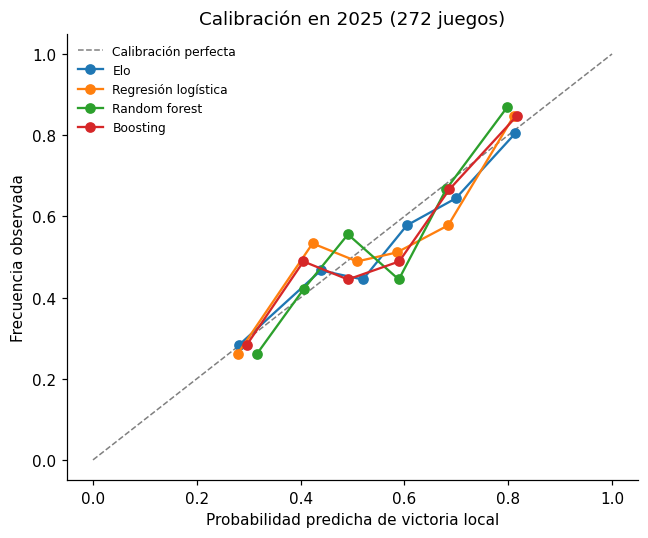

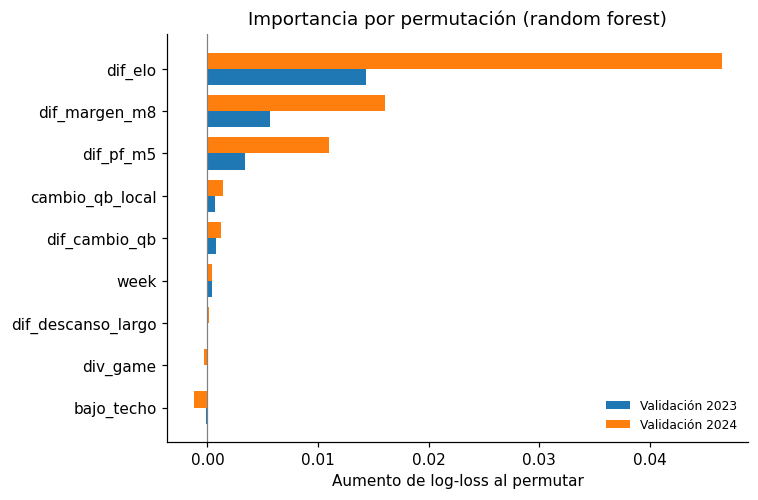

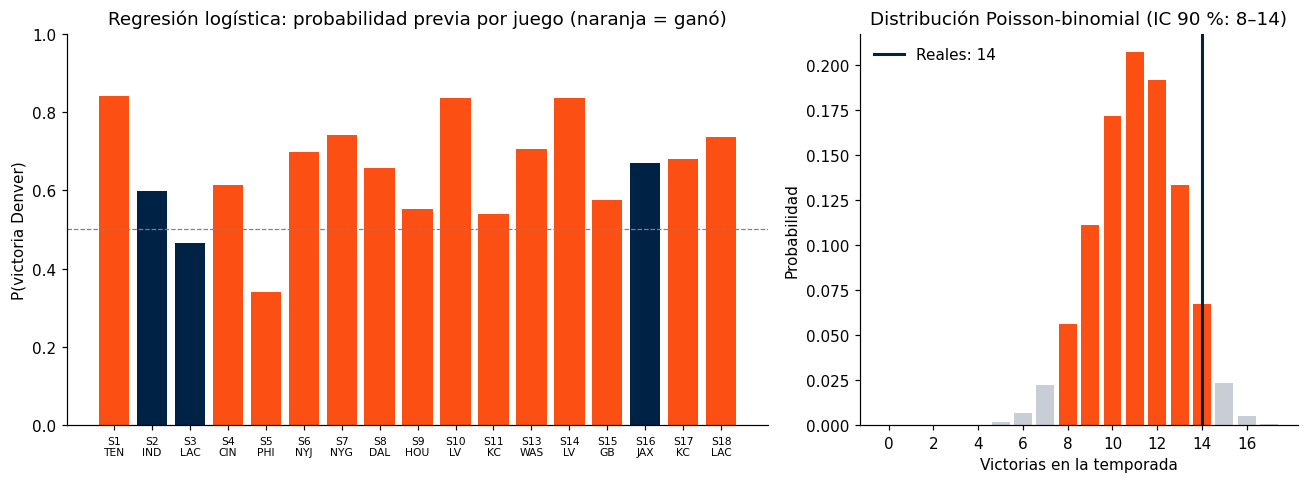


Resultados guardados en 'resultados/'


In [31]:
graficar(prueba, preds, tabla_imp, den, mejor, victorias, SALIDA)

with open(f"{SALIDA}/resumen.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2, default=str)
print(f"\nResultados guardados en '{SALIDA}/'")

## Marcador: evaluación en 2025
Se compara contra una base (promedios del entrenamiento), el Elo convertido a puntos y las apuestas (spread y
over/under). El IC 95 % de ΔMAE (modelo − base) también remuestrea semanas.

In [32]:
preds_m = {
    "Base (promedios)": pred_referencia(prueba_m, "base", ent_m),
    "Elo (dif/25)": pred_referencia(prueba_m, "elo", ent_m, modelo.sigma_margen),
    "Modelo": modelo.predict(prueba_m),
    "Apuestas (referencia)": pred_referencia(prueba_m, "apuestas", sigma=modelo.sigma_margen),
}
tabla = pd.DataFrame([evaluar(prueba_m, p, n) for n, p in preds_m.items()])
semanas = prueba_m["week"].to_numpy()
# IC 95 % de ΔMAE, modelo contra base
for obj, col in [("margen", "margen_pred"), ("total", "total_pred")]:
    err_m = np.abs(prueba_m[obj].to_numpy() - preds_m["Modelo"][col].to_numpy())
    err_b = np.abs(prueba_m[obj].to_numpy() - preds_m["Base (promedios)"][col].to_numpy())
    lo, hi = bootstrap_mae(semanas, err_m, err_b, BOOTSTRAP, rng_m)
    resumen_m[f"IC95_ΔMAE_{obj}_modelo_vs_base"] = [round(lo, 3), round(hi, 3)]
tabla.to_csv(f"{SALIDA_MARCADOR}/evaluacion_2025.csv", index=False)
resumen_m["evaluacion_2025"] = tabla.round(3).to_dict(orient="records")
print(f"\nEvaluación en {TEMPORADA_PRUEBA} ({len(prueba_m)} juegos)")
print(tabla.round(2).to_string(index=False))
print("IC 95 % de ΔMAE (modelo − base), bootstrap por semanas:",
      {k: v for k, v in resumen_m.items() if k.startswith("IC95")})


Evaluación en 2025 (272 juegos)
               modelo  MAE_margen  MAE_total  MAE_pts_local  MAE_pts_visita  acierta_ganador_%  margen_a_7_pts_%  log_loss_ganador
     Base (promedios)       11.06      10.97           7.78            7.97              53.87             43.75              0.69
         Elo (dif/25)       10.24      10.97           7.33            7.83              64.21             41.54              0.64
               Modelo       10.26      10.83           7.27            7.78              61.25             43.01              0.63
Apuestas (referencia)        9.72      10.39           7.26            7.23              65.31             45.59              0.61
IC 95 % de ΔMAE (modelo − base), bootstrap por semanas: {'IC95_ΔMAE_margen_modelo_vs_base': [np.float64(-1.401), np.float64(-0.205)], 'IC95_ΔMAE_total_modelo_vs_base': [np.float64(-0.424), np.float64(0.11)]}


In [33]:
pm = preds_m["Modelo"]
den_m = prueba_m[(prueba_m["home_team"] == EQUIPO) | (prueba_m["away_team"] == EQUIPO)]
tabla_den = formatear(den_m, pm.loc[den_m.index], con_real=True)
tabla_den.to_csv(f"{SALIDA_MARCADOR}/denver_{TEMPORADA_PRUEBA}.csv", index=False)
print(f"\nDenver {TEMPORADA_PRUEBA}: marcador predicho vs real")
print(tabla_den.to_string(index=False))


Denver 2025: marcador predicho vs real
 semana      fecha visita local  pred rango_80%_visita rango_80%_local  P(gana local)  real  acierta_ganador
      1 2025-09-07    TEN   DEN 18–30             7–30           17–42           0.81 12–20             True
      2 2025-09-14    DEN   IND 26–25            15–38           13–37           0.46 28–29            False
      3 2025-09-21    DEN   LAC 24–25            13–36           13–37           0.53 20–23             True
      4 2025-09-29    CIN   DEN 20–25             9–32           13–37           0.65  3–28             True
      5 2025-10-05    DEN   PHI 22–26            11–34           14–38           0.61 21–17            False
      6 2025-10-12    DEN   NYJ 27–19            15–38            7–31           0.28 13–11             True
      7 2025-10-19    NYG   DEN 20–28             8–32           15–39           0.71 32–33             True
      8 2025-10-26    DAL   DEN 23–28            11–35           16–40           0.66 24

**Resultado.** En 2025 el modelo reduce el MAE del margen de 11.06 a 10.26 puntos (IC 95 % de la diferencia: −1.40 a −0.21), pero no el del total: 10.83 frente a 10.97, con IC de −0.42 a 0.11, que incluye el cero. Con estos atributos, cuántos puntos se anotan en un juego es casi ruido alrededor del promedio de la liga. El error por equipo es de unos 7.5 puntos, y las apuestas siguen siendo mejores en todas las métricas.

## Temporada 2026: evaluación de lo jugado y pronóstico de lo pendiente
Con el modelo entrenado hasta 2025 se evalúan los 158 juegos ya jugados de 2026. Luego se reentrena con todo lo jugado
y se pronostican los juegos pendientes; el pronóstico de la semana 11 se guarda en `pronosticos/` para revisarlo
después del juego (Revisión del pronóstico).

In [34]:
actual = dm[dm["season"] == TEMPORADA_ACTUAL]
if len(actual):
    hasta_2025 = jugados_m[jugados_m["season"] <= TEMPORADA_PRUEBA]
    modelo_final = ModeloMarcador(sel["margen"], sel["total"]).fit(hasta_2025)
    jug_act = actual[actual["pendiente"] == 0]
    if len(jug_act):
        t_act = pd.DataFrame([
            evaluar(jug_act, modelo_final.predict(jug_act), "Modelo"),
            evaluar(jug_act, pred_referencia(jug_act, "apuestas", sigma=modelo.sigma_margen),
                    "Apuestas (referencia)")])
        t_act.to_csv(f"{SALIDA_MARCADOR}/evaluacion_{TEMPORADA_ACTUAL}_jugados.csv", index=False)
        resumen_m[f"evaluacion_{TEMPORADA_ACTUAL}_jugados"] = t_act.round(3).to_dict(orient="records")
        print(f"\n{TEMPORADA_ACTUAL}, juegos ya jugados ({len(jug_act)}), modelo entrenado 2015–2025")
        print(t_act.round(2).to_string(index=False))

    # para pronosticar se reentrena con todo lo jugado
    modelo_pron = ModeloMarcador(sel["margen"], sel["total"]).fit(jugados_m)
    pend = actual[actual["pendiente"] == 1]
    if len(pend):
        pp = modelo_pron.predict(pend)
        proxima = pend["week"].min()
        todos = formatear(pend, pp, con_real=False)
        todos.to_csv(f"{SALIDA_MARCADOR}/pronostico_{TEMPORADA_ACTUAL}_pendientes.csv", index=False)
        guardar_pronostico(pend, pp, proxima, TEMPORADA_ACTUAL)
        sem = formatear(pend[pend["week"] == proxima], pp.loc[pend["week"] == proxima], con_real=False)
        den_p = pend[(pend["home_team"] == EQUIPO) | (pend["away_team"] == EQUIPO)]
        tabla_den_p = formatear(den_p, pp.loc[den_p.index], con_real=False)
        tabla_den_p.to_csv(f"{SALIDA_MARCADOR}/pronostico_denver_{TEMPORADA_ACTUAL}.csv", index=False)
        print(f"\nPronóstico semana {proxima} de {TEMPORADA_ACTUAL}")
        print(sem.to_string(index=False))
        print(f"\nPronóstico de los juegos pendientes de Denver en {TEMPORADA_ACTUAL}")
        print(tabla_den_p.to_string(index=False))
        resumen_m["pronostico_denver"] = tabla_den_p.to_dict(orient="records")


2026, juegos ya jugados (158), modelo entrenado 2015–2025
               modelo  MAE_margen  MAE_total  MAE_pts_local  MAE_pts_visita  acierta_ganador_%  margen_a_7_pts_%  log_loss_ganador
               Modelo        9.63      11.37           7.21            8.02              65.61             47.47              0.61
Apuestas (referencia)        9.42      10.46           6.80            7.72              69.43             49.37              0.61
Pronóstico guardado en pronosticos/pronostico_2026_semana11_generado_2026-11-22.csv (se revisa en «Revisión del pronóstico»)

Pronóstico semana 11 de 2026
 semana      fecha visita local  pred rango_80%_visita rango_80%_local  P(gana local)  apuestas
     11 2026-11-22    JAX   NYG 27–22            15–39            9–34           0.35 25.8–19.8
     11 2026-11-22     LV   DEN 18–29             7–30           17–41           0.78 15.0–26.5
     11 2026-11-22    MIN    SF 23–25            11–35           13–37           0.58 21.5–25.0
     11 2

**Resultado.** En los 158 juegos ya jugados de 2026, el modelo entrenado hasta 2025 acierta el ganador el 65.6 % de las veces, frente al 69.4 % de las apuestas, con un log-loss prácticamente igual (0.609 frente a 0.608). Para la semana 11 el modelo da a Denver como favorito contra Las Vegas: 18–29 con P = 0.78. Ese pronóstico quedó guardado antes del juego.

## Calibración de los rangos del 80 % y variabilidad de la exactitud
Si los rangos del 80 % están bien calibrados, alrededor del 80 % de los puntajes reales debe caer dentro. La exactitud
del ganador se acompaña de un IC 95 % por bootstrap de semanas.

In [35]:
def cobertura(juegos, pred):
    """Fracción de puntajes reales dentro del rango del 80 %."""
    dentro_local = juegos["home_score"].between(pred["local_p10"], pred["local_p90"])
    dentro_visita = juegos["away_score"].between(pred["visita_p10"], pred["visita_p90"])
    return float(np.r_[dentro_local, dentro_visita].mean())


def ic_exactitud(juegos, pred, rng, B=BOOTSTRAP):
    """Exactitud del ganador e IC 95 % por semanas."""
    acierto = (np.sign(pred["margen_pred"].to_numpy()) == np.sign(juegos["margen"].to_numpy())).astype(float)
    muestras = [acierto[f].mean() for f in remuestreo_semanas(juegos["week"].to_numpy(), B, rng)]
    return acierto.mean(), np.percentile(muestras, [2.5, 97.5])


pred_2026 = modelo_final.predict(jug_act)
rng_exac = np.random.default_rng(SEMILLA)
for etiqueta, juegos, pred in [("2025 (prueba)", prueba_m, preds_m["Modelo"]), ("2026 (jugados)", jug_act, pred_2026)]:
    exac, (lo, hi) = ic_exactitud(juegos, pred, rng_exac)
    print(f"{etiqueta:15s} cobertura del rango 80 %: {cobertura(juegos, pred):.1%}   "
          f"exactitud del ganador: {exac:.1%} (IC 95 %: {lo:.1%}–{hi:.1%})")
print(f"Desviación del error de margen usada para la probabilidad: {modelo.sigma_margen:.2f} puntos")

2025 (prueba)   cobertura del rango 80 %: 77.8%   exactitud del ganador: 61.0% (IC 95 %: 54.8%–66.4%)
2026 (jugados)  cobertura del rango 80 %: 80.4%   exactitud del ganador: 65.2% (IC 95 %: 57.4%–74.2%)
Desviación del error de margen usada para la probabilidad: 13.21 puntos


**Resultado.** Los rangos del 80 % contienen el 77.8 % de los puntajes en 2025 y el 80.4 % en 2026: están bien calibrados en promedio, aunque tienen el mismo ancho en todos los juegos. La exactitud del ganador tiene intervalos amplios (55–66 % en 2025 y 57–74 % en 2026): con una temporada de prueba, diferencias de un par de puntos entre modelos no son concluyentes.

## Revisión del pronóstico: LV @ DEN, 22 nov 2026
Este paso corresponde a `revisar_pronostico.py`: compara el pronóstico guardado en la sección anterior (antes de los juegos) contra
los resultados de la copia de datos del 24 nov. Un solo juego no valida el modelo; sirve para ver cómo se interpreta
un pronóstico.

In [36]:
def revisar(ruta=None, equipo=None, datos=DATOS_RESULTADOS):
    """Compara un pronóstico guardado contra los resultados reales."""
    ruta = ruta or max(glob.glob("pronosticos/pronostico_*.csv"), key=os.path.getmtime, default=None)
    if ruta is None:
        raise FileNotFoundError("No hay pronósticos guardados; ejecuta antes la sección de la temporada 2026")
    pron = pd.read_csv(ruta)
    print(f"Pronóstico: {ruta}")

    reales = cargar_datos(datos)
    reales = reales[["game_id", "away_score", "home_score"]]
    t = pron.merge(reales, on="game_id", how="left")
    if equipo:
        t = t[(t["local"] == equipo) | (t["visita"] == equipo)]

    pendientes = t[t["home_score"].isna()]
    t = t[t["home_score"].notna()].copy()
    if len(pendientes):
        print(f"Aún sin resultado en nflverse: "
              + ", ".join(f"{v} @ {l}" for v, l in zip(pendientes["visita"], pendientes["local"]))
              + "\n(nflverse suele actualizar unas horas después de cada juego)")
    if t.empty:
        return

    # errores y cobertura por juego
    margen_pred = t["pts_local_pred"] - t["pts_visita_pred"]
    margen_real = t["home_score"] - t["away_score"]
    t["acierta_ganador"] = np.sign(margen_pred) == np.sign(margen_real)
    t["err_local"] = (t["home_score"] - t["pts_local_pred"]).round(1)
    t["err_visita"] = (t["away_score"] - t["pts_visita_pred"]).round(1)
    t["local_en_rango80"] = t["home_score"].between(t["local_p10"], t["local_p90"])
    t["visita_en_rango80"] = t["away_score"].between(t["visita_p10"], t["visita_p90"])
    t["apuestas_acierta"] = np.where(t["spread_line"].notna(),
                                     np.sign(t["spread_line"]) == np.sign(margen_real), np.nan)

    vista = pd.DataFrame({
        "juego": t["visita"] + " @ " + t["local"],
        "predicho": t["pts_visita_pred"].round().astype(int).astype(str) + "–"
                    + t["pts_local_pred"].round().astype(int).astype(str),
        "real": t["away_score"].astype(int).astype(str) + "–" + t["home_score"].astype(int).astype(str),
        "P(local)": t["p_local"],
        "ganador": np.where(t["acierta_ganador"], "✓", "✗"),
        "error visita/local": t["err_visita"].astype(str) + " / " + t["err_local"].astype(str),
        "en rango 80 %": np.where(t["visita_en_rango80"] & t["local_en_rango80"], "ambos",
                                  np.where(t["visita_en_rango80"] | t["local_en_rango80"], "uno", "ninguno")),
    })
    print()
    print(vista.to_string(index=False))

    n = len(t)
    print(f"\nResumen de {n} juego(s):")
    print(f"  Ganador acertado:           {t['acierta_ganador'].sum()}/{n}")
    if t["apuestas_acierta"].notna().any():
        print(f"  Ganador según apuestas:     {int(np.nansum(t['apuestas_acierta']))}/{t['apuestas_acierta'].notna().sum()}")
    print(f"  Error medio por equipo:     {np.mean(np.abs(np.r_[t['err_local'], t['err_visita']])):.1f} puntos")
    dentro = np.r_[t["local_en_rango80"], t["visita_en_rango80"]].mean()
    print(f"  Puntajes dentro del 80 %:   {100 * dentro:.0f} % (lo esperado es ~80 %)")
    salida = ruta.replace(".csv", "_revisado.csv")
    t.to_csv(salida, index=False)
    print(f"\nDetalle guardado en {salida}")
    return t

In [37]:
pronostico_domingo = f"pronosticos/pronostico_{TEMPORADA_ACTUAL}_semana11_generado_{FECHA_DATOS}.csv"
revisado = revisar(pronostico_domingo)

Pronóstico: pronosticos/pronostico_2026_semana11_generado_2026-11-22.csv

    juego predicho  real  P(local) ganador error visita/local en rango 80 %
JAX @ NYG    27–22 18–23     0.350       ✗         -8.7 / 1.4         ambos
 LV @ DEN    18–29 24–38     0.782       ✓          5.5 / 9.2         ambos
 MIN @ SF    23–25 10–35     0.577       ✓        -12.6 / 9.8           uno
NYJ @ LAC    22–24 27–24     0.557       ✗          5.2 / 0.2         ambos
CIN @ WAS    25–20 20–22     0.360       ✗         -4.8 / 1.9         ambos

Resumen de 5 juego(s):
  Ganador acertado:           2/5
  Ganador según apuestas:     2/5
  Error medio por equipo:     5.9 puntos
  Puntajes dentro del 80 %:   90 % (lo esperado es ~80 %)

Detalle guardado en pronosticos/pronostico_2026_semana11_generado_2026-11-22_revisado.csv


In [38]:
den_dom = revisado[revisado["local"] == EQUIPO].iloc[0]
print(f"Pronóstico: LV {den_dom['pts_visita_pred']:.0f} – DEN {den_dom['pts_local_pred']:.0f}, "
      f"P(gana DEN) = {den_dom['p_local']:.0%}")
print(f"Rango 80 %: LV {den_dom['visita_p10']:.0f}–{den_dom['visita_p90']:.0f}, "
      f"DEN {den_dom['local_p10']:.0f}–{den_dom['local_p90']:.0f}")
print(f"Apuestas: DEN por {den_dom['spread_line']}, total {den_dom['total_line']}")
print(f"Real: LV {den_dom['away_score']:.0f} – DEN {den_dom['home_score']:.0f}  "
      f"(total predicho {den_dom['pts_visita_pred'] + den_dom['pts_local_pred']:.0f} vs real "
      f"{den_dom['away_score'] + den_dom['home_score']:.0f})")

Pronóstico: LV 18 – DEN 29, P(gana DEN) = 78%
Rango 80 %: LV 7–30, DEN 17–41
Apuestas: DEN por 11.5, total 41.5
Real: LV 24 – DEN 38  (total predicho 47 vs real 62)


**Resultado.** El modelo pronosticó 18–29 con 78 % para Denver y el juego terminó 24–38: acertó el ganador y los dos puntajes cayeron en su rango del 80 %, pero subestimó el total (47 frente a 62), igual que las apuestas (41.5). En los cinco juegos de esa tarde acertó 2 ganadores, igual que las apuestas, y 9 de 10 puntajes cayeron en su rango. Acertar el juego de Denver no valida el modelo, como tampoco lo habría invalidado un error: con P = 0.78, Denver perdería uno de cada cinco juegos así. La evidencia está en la evaluación de cientos de juegos.

## Figuras del artículo Reporte
Las tres figuras del reporte se generan aquí a partir de los resultados anteriores (sin reentrenar), y se guardan en
`articulo/fig/` para incluirlas en el reporte.

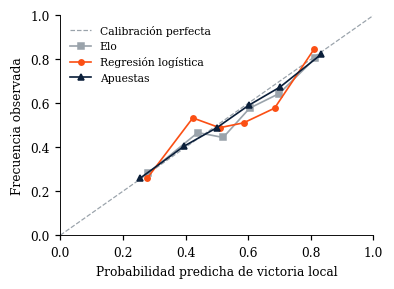

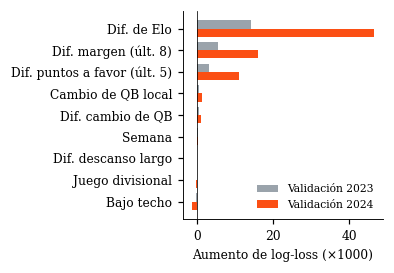

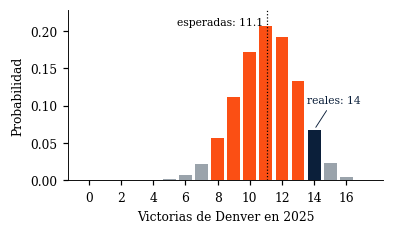

In [39]:
os.makedirs("articulo/fig", exist_ok=True)
NAVY, NARANJA, GRIS = "#0B1F3A", "#FB4F14", "#9AA3AB"
ANCHO = 3.45  # ancho de una columna, en pulgadas
estilo = {"font.size": 8, "font.family": "serif", "axes.spines.top": False, "axes.spines.right": False,
          "axes.linewidth": 0.6}

with plt.rc_context(estilo):
    fig, ax = plt.subplots(figsize=(ANCHO, 2.5))
    ax.plot([0, 1], [0, 1], ls="--", c=GRIS, lw=0.8, label="Calibración perfecta")
    for p, nombre, color, marca in [(prueba["prob_elo"].to_numpy(), "Elo", GRIS, "s"),
                                    (preds[mejor], mejor, NARANJA, "o"),
                                    (prob_apuestas(prueba).to_numpy(), "Apuestas", NAVY, "^")]:
        fp, mp = calibration_curve(prueba["y"], p, n_bins=6, strategy="quantile")
        ax.plot(mp, fp, marker=marca, ms=3.5, lw=1.1, c=color, label=nombre)
    ax.set(xlabel="Probabilidad predicha de victoria local", ylabel="Frecuencia observada", xlim=(0, 1), ylim=(0, 1))
    ax.legend(frameon=False, fontsize=7, loc="upper left")
    fig.tight_layout(pad=0.3); fig.savefig("articulo/fig/calibracion.pdf"); plt.show()
    etiquetas = {"dif_elo": "Dif. de Elo", "dif_margen_m8": "Dif. margen (últ. 8)",
               "dif_pf_m5": "Dif. puntos a favor (últ. 5)", "cambio_qb_local": "Cambio de QB local",
               "dif_cambio_qb": "Dif. cambio de QB", "week": "Semana", "dif_descanso_largo": "Dif. descanso largo",
               "div_game": "Juego divisional", "bajo_techo": "Bajo techo"}
    imp = tabla_imp.iloc[::-1]
    y = np.arange(len(imp))
    fig, ax = plt.subplots(figsize=(ANCHO, 2.35))
    ax.barh(y + 0.19, imp["valida_2023"] * 1000, 0.38, color=GRIS, label="Validación 2023")
    ax.barh(y - 0.19, imp["valida_2024"] * 1000, 0.38, color=NARANJA, label="Validación 2024")
    ax.set_yticks(y, [etiquetas.get(i, i) for i in imp.index]); ax.axvline(0, c="k", lw=0.5)
    ax.set_xlabel("Aumento de log-loss (×1000)"); ax.legend(frameon=False, fontsize=7, loc="lower right")
    fig.tight_layout(pad=0.3); fig.savefig("articulo/fig/importancia.pdf"); plt.show()

    p = den[f"p_{mejor}"].to_numpy()
    dist = poisson_binomial(p)
    lo, hi = intervalo(dist)
    k = np.arange(len(dist))
    colores = [NARANJA if lo <= i <= hi else GRIS for i in k]
    colores[victorias] = NAVY
    fig, ax = plt.subplots(figsize=(ANCHO, 2.0))
    ax.bar(k, dist, color=colores, width=0.8)
    ax.axvline(p.sum(), c="k", ls=":", lw=0.8)
    ax.text(p.sum() - 0.25, dist.max(), f"esperadas: {p.sum():.1f}", fontsize=7, ha="right")
    ax.annotate(f"reales: {victorias}", xy=(victorias, dist[victorias]), xytext=(victorias + 1.2, 0.5 * dist.max()), fontsize=7,
                color=NAVY, ha="center", arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.6))
    ax.set(xlabel="Victorias de Denver en 2025", ylabel="Probabilidad", xticks=k[::2], ylim=(0, 1.1 * dist.max()))
    fig.tight_layout(pad=0.3); fig.savefig("articulo/fig/denver.pdf"); plt.show()

## Gráficas y resumen de la extensión

In [40]:
def graficar_marcador(prueba, preds, tabla_den, salida):
    """Predicho contra real en 2025 y marcadores de Denver."""
    plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
    pm = preds["Modelo"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    for ax, obj, col, titulo in [(axes[0], "margen", "margen_pred", "Margen (local − visita)"),
                                 (axes[1], "total", "total_pred", "Puntos totales")]:
        ax.scatter(pm[col], prueba[obj], s=14, alpha=0.6, color="#FB4F14", edgecolor="none")
        lo = min(pm[col].min(), prueba[obj].min()); hi = max(pm[col].max(), prueba[obj].max())
        ax.plot([lo, hi], [lo, hi], ls="--", c="grey", lw=1)
        mae = mean_absolute_error(prueba[obj], pm[col])
        ax.set(xlabel="Predicho", ylabel="Real", title=f"{titulo} en {TEMPORADA_PRUEBA} (MAE {mae:.1f})")
    fig.tight_layout(); fig.savefig(f"{salida}/predicho_vs_real_2025.png", dpi=150); plt.show()

    den_local = tabla_den["local"] == EQUIPO
    pred = tabla_den["pred"].str.split("–", expand=True).astype(float)
    real = tabla_den["real"].str.split("–", expand=True).astype(float)
    den_pred = np.where(den_local, pred[1], pred[0]); riv_pred = np.where(den_local, pred[0], pred[1])
    den_real = np.where(den_local, real[1], real[0]); riv_real = np.where(den_local, real[0], real[1])
    rival = np.where(den_local, tabla_den["visita"], tabla_den["local"])
    x = np.arange(len(tabla_den))
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.bar(x - 0.2, den_real, 0.4, color="#FB4F14", label="Denver real")
    ax.bar(x + 0.2, riv_real, 0.4, color="#C9CED6", label="Rival real")
    ax.scatter(x - 0.2, den_pred, marker="_", s=300, c="#002244", lw=3, label="Predicho", zorder=3)
    ax.scatter(x + 0.2, riv_pred, marker="_", s=300, c="#002244", lw=3, zorder=3)
    ax.set_xticks(x, [f"S{s}\n{r}" for s, r in zip(tabla_den["semana"], rival)], fontsize=8)
    ax.set(ylabel="Puntos", title=f"Denver {TEMPORADA_PRUEBA}: marcador real (barras) y predicho (líneas)")
    ax.legend(frameon=False, ncol=3)
    fig.tight_layout(); fig.savefig(f"{salida}/denver_marcadores_2025.png", dpi=150); plt.show()

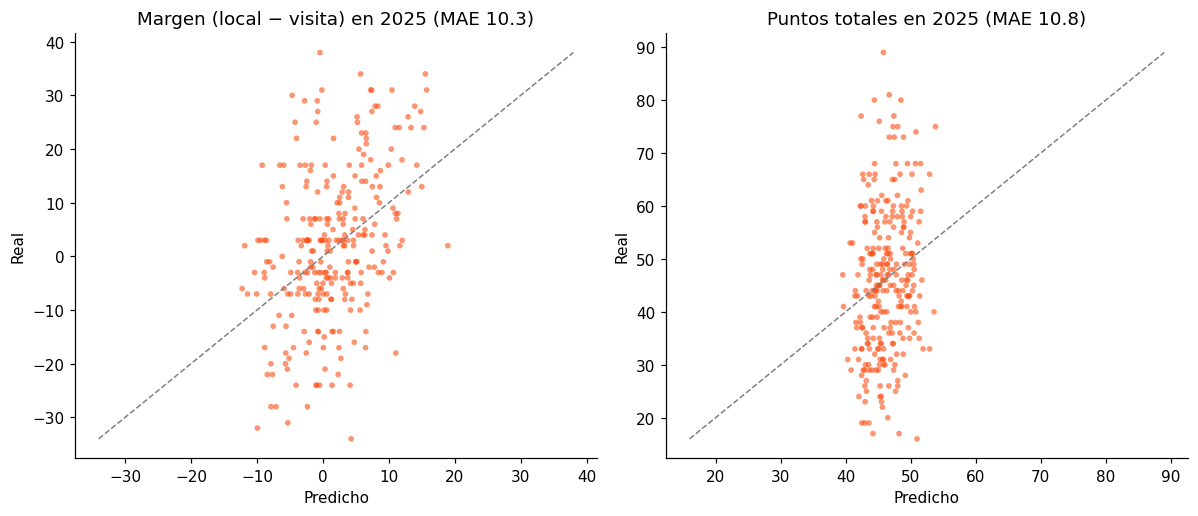

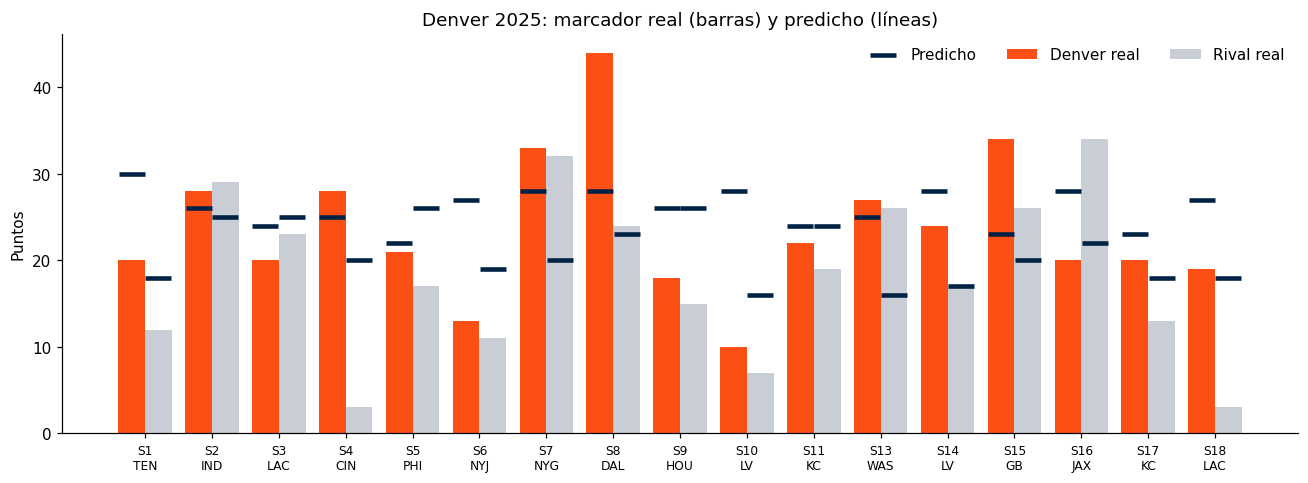


Resultados guardados en 'resultados_marcador/'


In [41]:
graficar_marcador(prueba_m, preds_m, tabla_den, SALIDA_MARCADOR)
with open(f"{SALIDA_MARCADOR}/resumen.json", "w", encoding="utf-8") as f:
    json.dump(resumen_m, f, ensure_ascii=False, indent=2, default=str)
print(f"\nResultados guardados en '{SALIDA_MARCADOR}/'")

# Conclusiones

**Lo que mostraron los números de esta ejecución:**

- *¿Supera el modelo a la línea base en 2025?.* La regresión logística, elegida en validación, baja el log-loss de 0.691 a 0.632 en 2025 (IC 95 % de la diferencia: −0.090 a −0.026); Elo, random forest (0.620) y boosting también superan a la base, y Naive Bayes no. El Elo solo ya logra 0.638, y las apuestas, 0.608.
- *¿Qué atributos son más influyentes?.* La diferencia de Elo (0.030) casi triplica al margen de los últimos 8 juegos (0.011); el top 5 es el mismo en los pliegues de 2023 y 2024.
- *¿Anticipa el modelo el desempeño de Denver en 2025?* 11.1 victorias esperadas (logística), intervalo del 90 % de 8 a 14, 14 reales; P(≥ 14) = 9.6 %.
- *Extensión, marcador.* MAE del margen 10.26 contra 11.06 de la base (mejora significativa); MAE del total 10.83 contra 10.97 (no significativa). Rangos del 80 % con cobertura de 77.8 % (2025) y 80.4 % (2026). En 2026, 65.6 % de ganadores contra 69.4 % de las apuestas.
- *Juego del 22 nov 2026.* Pronóstico LV 18 – DEN 29 (P = 0.78); real 24–38. Ganador y rangos acertados; total subestimado; 2 de 5 ganadores esa tarde.

**Qué significan los resultados.**

* **El desempeño reciente sí contiene información**, pero moderada. La mejora sobre la base es real (no se explica por el azar de unas semanas) y casi toda viene de un solo número, el Elo. Un modelo más complejo agrega poco sobre esa señal, y no se puede afirmar que la logística supere al Elo porque esa comparación no se probó.
* **El techo lo pone el azar del deporte.** Acertar entre 61 y 66 % de los ganadores no es una falla del modelo: las apuestas, con mucha más información, llegan al 65–69 %. Por eso la métrica relevante es la calidad de la probabilidad (log-loss, calibración) y no el porcentaje de aciertos.
* **El orden de los atributos es estable, pero no causal.** Lo que se concluye es qué atributos ayudan a predecir dado el resto, no qué factores deciden un juego.
* **Denver 2025 fue un año por encima de lo esperado** para todos los modelos y para el mercado. Con una sola temporada no se puede separar un sesgo del modelo de un año excepcional.
* **El marcador es un valor esperado, no un resultado exacto.** El margen se predice mejor que con promedios; el total no. Los rangos del 80 % están bien calibrados, y son la forma correcta de leer un pronóstico como 18–29.

**Limitaciones.** Solo datos públicos a nivel marcador (sin lesiones, alineaciones ni estadísticas por jugada); una temporada de prueba de 272 juegos; hiperparámetros elegidos con dos pliegues; un bootstrap que trata las semanas como independientes; error normal y rangos de ancho fijo en el marcador; y resultados que dependen de la copia congelada de los datos.

**Trabajo futuro.** Agregar EPA por jugada y lesiones (también publicados por nflverse), intervalos que varíen por juego y seguir revisando el pronóstico semanal de 2026.

# Referencias

Boulier, B. L., & Stekler, H. O. (2003). Predicting the outcomes of National Football League games. International Journal of Forecasting, 19(2), 257–270. https://doi.org/10.1016/S0169-2070(01)00144-3

Breiman, L. (2001). Random forests. Machine Learning, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324

Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. Monthly Weather Review, 78(1), 1–3.

Efron, B., & Tibshirani, R. J. (1993). An introduction to the bootstrap. Chapman & Hall.

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. The Annals of Statistics, 29(5), 1189–1232.

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830.

Sharpe, L., et al. (s. f.). nfldata: NFL game data [Conjunto de datos]. nflverse. https://github.com/nflverse/nfldata

Silver, N. (s. f.). How our NFL predictions work. FiveThirtyEight. https://fivethirtyeight.com/methodology/how-our-nfl-predictions-work/

Stern, H. (1991). On the probability of winning a football game. The American Statistician, 45(3), 179–183.

Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. Journal of the Royal Statistical Society: Series B, 58(1), 267–288.

# Declaración de uso de IA

Para esta práctica se utilizó la inteligencia artificial Anthropic Claude como herramienta de asistencia para la revisión, edición y mejora del formato de texto, así como el apoyo en la toma de sugerencias para la parte del código y la corrección de errores.